## Setup
Imports, particle masses and helper functions used throughout the notebook.

In [57]:
import pickle
import numpy as np
import pandas
from matplotlib import pyplot as plt
from tabulate import tabulate
import zfit

#Particle masses in MeV/c^2 (PDG values)
M_KAON  = 493.7
M_MUON  = 105.7
M_PION  = 139.6
M_JPSI  = 3097
M_PSI2S = 3686
M_D0    = 1864.8

In [58]:
def track_energy(data, track, mass):
    #Energy of a track given the mass we choose. mass=None uses the energy stored in the data.
    if mass is None:
        return data[f'{track} 4-momentum energy component']
    p = [data[f'{track} 4-momentum {c} component'] for c in 'xyz']
    return np.sqrt(p[0]**2 + p[1]**2 + p[2]**2 + mass**2)


def two_body_mass(data, track1, track2, mass1=None, mass2=None):
    #Invariant mass of two tracks, where we choose which mass each track is given.
    #track names are 'Kaon', 'Opposite-sign muon' or 'Same-sign muon'.
    #Changing mass1/mass2 lets us test what happens if a particle was misidentified.
    p1 = [data[f'{track1} 4-momentum {c} component'] for c in 'xyz']
    p2 = [data[f'{track2} 4-momentum {c} component'] for c in 'xyz']

    energy1 = track_energy(data, track1, mass1)
    energy2 = track_energy(data, track2, mass2)

    combined_energy = energy1 + energy2
    combined_momentum_sq = (p1[0] + p2[0])**2 + (p1[1] + p2[1])**2 + (p1[2] + p2[2])**2
    return np.sqrt(combined_energy**2 - combined_momentum_sq)


def plot_mass(values, xlabel, title=None, show_peak=False, bins=100, **hist_kwargs):
    #Histogram of a mass, with the y-axis label showing the real bin width.
    #show_peak=True marks the centre of the tallest bin.
    counts, edges, _ = plt.hist(values, bins=bins, **hist_kwargs)
    bin_width = edges[1] - edges[0]

    if show_peak:
        i = np.argmax(counts)
        peak = 0.5 * (edges[i] + edges[i + 1])
        plt.axvline(peak, linestyle='--', color='red', label=f'Peak: {peak:.0f} MeV')
        plt.legend()

    if title:
        plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
    plt.show()


def plot_fit(values, model, components=None, bins=100, xlabel=r'Mass / MeV/$c^2$', title=None, show_pulls=False):
    #Draw data as a filled histogram with an already-fitted zfit model (and optionally its parts) on top.
    #fit_and_plot uses this, and it can be used on its own when a fit was done another way
    #(e.g. the B+ and B- fit below, which fits two datasets at once).
    lower = float(np.ravel(model.space.lower)[0])
    upper = float(np.ravel(model.space.upper)[0])
    values = np.asarray(values)
    in_range = values[(values >= lower) & (values <= upper)]

    #Turn a PDF (which integrates to 1) into candidates per bin
    counts, edges = np.histogram(in_range, bins=bins, range=(lower, upper))
    bin_width = edges[1] - edges[0]
    centres = 0.5 * (edges[1:] + edges[:-1])

    def candidates_per_bin(pdf, x):
        if pdf.is_extended:
            return np.asarray(pdf.ext_pdf(x)) * bin_width
        if pdf is model:
            return np.asarray(pdf.pdf(x)) * len(in_range) * bin_width
        raise ValueError('Components must have their own yield (extended=...) so they can be drawn.')

    if show_pulls:
        fig, (ax, ax_pull) = plt.subplots(2, 1, sharex=True, figsize=(6.4, 6), gridspec_kw={'height_ratios': [3, 1]})
    else:
        fig, ax = plt.subplots()

    #Data as a filled histogram, fits as lines on top
    ax.hist(in_range, bins=bins, range=(lower, upper), color='blue', label='Data')

    x = np.linspace(lower, upper, 1000)
    ax.plot(x, candidates_per_bin(model, x), 'r-', label='Total fit')
    for (label, pdf), style in zip((components or {}).items(), ['y--', 'g:', 'm-.', 'c--']):
        ax.plot(x, candidates_per_bin(pdf, x), style, label=label)

    ax.set_ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
    ax.legend()
    if title:
        ax.set_title(title)

    if show_pulls:
        #Pull = (data - fit) / error in each bin, using the fit value at the bin centre
        expected = candidates_per_bin(model, centres)
        errors = np.sqrt(counts)
        pulls = np.divide(counts - expected, errors, out=np.zeros(len(counts)), where=errors > 0)
        ax_pull.bar(centres, pulls, width=bin_width, color='grey')
        ax_pull.axhline(0, color='black', linewidth=0.8)
        for level in (-3, 3):
            ax_pull.axhline(level, color='red', linestyle='--', linewidth=0.8)
        ax_pull.set_ylabel('Pull')
        ax_pull.set_xlabel(xlabel)
    else:
        ax.set_xlabel(xlabel)

    plt.show()


def fit_and_plot(values, model, components=None, bins=100, xlabel=r'Mass / MeV/$c^2$', title=None, show_pulls=False):
    #Fit a zfit model to some data, print the result and plot the fit on top of the data.
    #values:     the data to fit, e.g. b_mass. Only the values inside the model's range are used.
    #model:      any zfit PDF you have built. If it has a yield (extended=...) an extended fit is done.
    #components: optional {label: pdf} of parts of the model to draw as well,
    #            e.g. {'Signal': signalPDF, 'Background': backgroundPDF}. Each part needs its own yield.
    #show_pulls: set to True to also draw (data - fit) / error for each bin underneath. Good fits scatter randomly around 0.
    #Returns the zfit fit result, so you can read off the fitted values with result.params[parameter]['value'].
    lower = float(np.ravel(model.space.lower)[0])
    upper = float(np.ravel(model.space.upper)[0])

    values = np.asarray(values)
    in_range = values[(values >= lower) & (values <= upper)]
    zdata = zfit.Data.from_numpy(obs=model.space, array=in_range)

    if model.is_extended:
        nll = zfit.loss.ExtendedUnbinnedNLL(model=model, data=zdata)
    else:
        nll = zfit.loss.UnbinnedNLL(model=model, data=zdata)

    result = zfit.minimize.Minuit().minimize(nll)
    #Uncertainties from Hesse (the curvature of the likelihood at the minimum)
    result.hesse()

    print(result)
    print(f"Converged: {result.converged}")
    print(f"Valid: {result.valid}")
    if not result.valid:
        print('WARNING: the fit is not valid, do not trust these numbers.')

    plot_fit(in_range, model, components, bins, xlabel, title, show_pulls)
    return result


## The datasets

All the files are in `../Data/`. They come in three kinds.

### 1. Real LHCb data
| File | Candidates | What it is |
|---|---|---|
| `dataset_2011` | 0.89 million | Collisions recorded in 2011 (7 TeV). Both magnet settings mixed together |
| `dataset_2012_MagnetDown` | 1.02 million | Collisions recorded in 2012 (8 TeV), magnet pointing down |
| `dataset_2012_MagnetUp` | 1.07 million | Collisions recorded in 2012 (8 TeV), magnet pointing up |

**What's in it:** each row is one *candidate*: a kaon and two muons of opposite charge that *might* have come from a B⁺ or B⁻.
Some are real B decays (mostly B → J/ψ K, some B → ψ(2S) K, and a few of the rare B → K μ⁺μ⁻ we want). The rest are background.

**What we use it for:**
- **The measurement itself.** Using all three files gives about 3× more events than 2011 alone, so a smaller error on A_CP.
- **Cross-checks.** The answer should not depend on the year or on the magnet setting. Flipping the magnet swaps which way K⁺ and K⁻ bend in the detector, so effects from one side of the detector being better than the other flip too. If magnet up and magnet down give the same A_CP, those effects are under control.

### 2. Same-sign data (background only)
| File | Candidates |
|---|---|
| `samesign_2011` | 41 thousand |
| `samesign_2012` | 123 thousand |

**What it is:** real data again, but chosen so that the **two muons have the same charge** (for example K⁺ μ⁻ μ⁻).
No real B decay gives this, because a muon pair from a B → K μμ decay (or from a J/ψ) always has one μ⁺ and one μ⁻.
So **every candidate here is fake**: random tracks that happened to be combined. We checked: there is no peak at the B mass and no J/ψ peak.

(Careful: the column names still say "Same-sign muon" and "Opposite-sign muon", but in these files both muons have the same charge.)

**What we use it for:**
- **A clean background sample for training XGBoost.** It is better than "B mass > 5700 MeV" because it covers the *whole* mass range, including right under the B peak.
- **The shape of the random-combination background** under the B peak, for choosing the background model in the fit.

It only describes *random-combination* background. It does **not** contain peaking backgrounds from misidentified particles (like the J/ψ kaon↔muon swap).

### 3. Simulation
| File | Events | What it is |
|---|---|---|
| `rapidsim_JpsiK` | 1 million | Simulated B⁺ → J/ψ K⁺, with J/ψ → μ⁺μ⁻ |
| `rapidsim_Kmumu` | 1 million | Simulated rare B⁺ → K⁺ μ⁺μ⁻ |

**What it is:** fake events made by a computer program (RapidSim), so we know exactly what each event really is.
It also has extra `(true)` columns: the real momentum of each particle *before* the detector smeared it.

**Limits:**
- Only B⁺ (no B⁻), so it **cannot** be used to measure an asymmetry.
- It is a fast, simplified simulation: 91 columns instead of 140. There are **no χ² variables, no PID scores and no isolation variables.** Three of our XGBoost variables are missing (`B decay vertex fit chi2`, `B impact parameter chi2 wrt primary vertex`, `B flight distance chi2 wrt primary vertex`), so we can't train our current XGBoost on it.
- The detector is simplified, so the peak may not be exactly the same width as in real data. Compare it with real J/ψ K events before relying on it.

**What we use it for:**
- **The shape of the signal peak** in the B mass fit, including its tail on the low-mass side.
- **Detector resolution:** compare the measured mass with the true mass.
- **How much signal our cuts throw away** (efficiency). For example, what fraction of rare decays are removed by the J/ψ and ψ(2S) vetoes.
- **Comparing the two decays.** E.g. check that the kaon momentum looks similar in J/ψ K and in K μμ, which is what makes the J/ψ K correction to A_CP work.

In [59]:
def load_dataset(name):
    with open(f'../Data/{name}.pkl', 'rb') as infile:
        return pickle.load(infile)

#Real data. Add a 'Year' column so we can still tell the files apart after combining them
#(the magnet setting is already stored in 'Magnet polarity': +1 = up, -1 = down)
real_files = {
    'dataset_2011':            2011,
    'dataset_2012_MagnetDown': 2012,
    'dataset_2012_MagnetUp':   2012,
}
real_parts = []
for name, year in real_files.items():
    part = load_dataset(name)
    part['Year'] = year
    real_parts.append(part)
data_all = pandas.concat(real_parts, ignore_index=True)
del real_parts   #free the memory used by the separate copies

#Same-sign data (background only)
samesign_parts = []
for name, year in {'samesign_2011': 2011, 'samesign_2012': 2012}.items():
    part = load_dataset(name)
    part['Year'] = year
    samesign_parts.append(part)
samesign_all = pandas.concat(samesign_parts, ignore_index=True)
del samesign_parts

#Simulation
sim_jpsik = load_dataset('rapidsim_JpsiK')
sim_kmumu = load_dataset('rapidsim_Kmumu')

In [60]:
#How many candidates are in each dataset
summary = [
    ('Real data, 2011',               (data_all['Year'] == 2011).sum()),
    ('Real data, 2012 magnet down',   ((data_all['Year'] == 2012) & (data_all['Magnet polarity'] == -1)).sum()),
    ('Real data, 2012 magnet up',     ((data_all['Year'] == 2012) & (data_all['Magnet polarity'] == 1)).sum()),
    ('Real data, total',              len(data_all)),
    ('Same-sign, 2011',               (samesign_all['Year'] == 2011).sum()),
    ('Same-sign, 2012',               (samesign_all['Year'] == 2012).sum()),
    ('Simulation, B -> J/psi K',      len(sim_jpsik)),
    ('Simulation, B -> K mu mu',      len(sim_kmumu)),
]
print(tabulate(summary, headers=['Dataset', 'Candidates']))

Dataset                        Candidates
---------------------------  ------------
Real data, 2011                    894996
Real data, 2012 magnet down       1023524
Real data, 2012 magnet up         1066069
Real data, total                  2984589
Same-sign, 2011                     41124
Same-sign, 2012                    122980
Simulation, B -> J/psi K          1000000
Simulation, B -> K mu mu          1000000


### Which data the analysis uses
The analysis below uses **all the real data** (2011 + 2012, both magnet settings): about 3.0 million candidates.
The same-sign background sample automatically uses the same years (Task 3).

To go back to 2011 only (faster, e.g. while testing changes), use the commented-out line in the cell below instead.
Running on all the data takes a while: the variable pruning in step 7 alone takes about 20–30 minutes, and the notebook needs about 10 GB of memory.

In [61]:
#All years. data_all already has a clean 0, 1, 2, ... index, so no copy is needed (a copy would use another ~3 GB of memory)
data = data_all
#data = data_all[data_all['Year'] == 2011].reset_index(drop=True)   #2011 only

#Shortcuts for the columns we use the most
b_mass      = data['B invariant mass']
dimuon_mass = data['dimuon-system invariant mass']

In [62]:
#We can look at all the types of information stored in this data
list(data)

['B decay vertex x position',
 'B decay vertex y position',
 'B decay vertex z position',
 'B decay vertex fit chi2',
 'B impact parameter wrt primary vertex',
 'B impact parameter chi2 wrt primary vertex',
 'B flight distance wrt primary vertex',
 'B flight distance chi2 wrt primary vertex',
 'B cos(angle) between line-of-flight and momentum',
 'B magnitude of momentum',
 'B magnitude of momentum transverse to beam',
 'B 4-momentum energy component',
 'B 4-momentum x component',
 'B 4-momentum y component',
 'B 4-momentum z component',
 'B invariant mass',
 'B assumed particle type',
 'B lifetime',
 'Isolation: Charged cone angle',
 'Isolation: Charged cone number of particles contained',
 'Isolation: Charged cone eta difference between cone momentum and B',
 'Isolation: Charged cone phi difference between cone momentum and B',
 'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
 'Isolation: Charged cone 4-momentum of max-PT object energy compon

## Task 1: B mass distribution and fit

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_43, Composed_autoparam_44]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1936635, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.7e-06 │      11217454.47 | -594487.9 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name               value  (rounded)        hesse    at limit
---------------  ------------------  -----------  ----------
signalYield             1.10782e+06  +/- 1.1e+03       False
backgroundYield              828814  +/- 9.9e+02       False
mean                        5283.57  +/-    0.02      

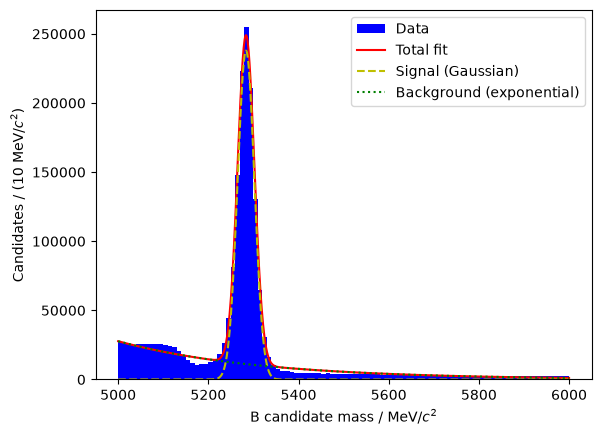

In [63]:
#Gaussian for the B peak plus an exponential for the background
b_mass_space = zfit.Space('B invariant mass', (5000, 6000))

mean  = zfit.Parameter('mean', 5280, 5000, 6000)
sigma = zfit.Parameter('sigma', 20,    5,  100)
signalYield = zfit.Parameter('signalYield', 1e6, 0, 1e7)

signalPDF = zfit.pdf.Gauss(obs=b_mass_space, mu=mean, sigma=sigma, extended=signalYield)

exponent  = zfit.Parameter('exponent', -0.01, -1e-1, -1e-6)
backgroundYield = zfit.Parameter('backgroundYield', 8e5, 0, 1e7)

backgroundPDF = zfit.pdf.Exponential(obs=b_mass_space, lam=exponent, extended=backgroundYield)

totalPDF = zfit.pdf.SumPDF(pdfs=[signalPDF, backgroundPDF])

result = fit_and_plot(b_mass, totalPDF,
                      components={'Signal (Gaussian)': signalPDF, 'Background (exponential)': backgroundPDF},
                      xlabel=r'B candidate mass / MeV/$c^2$')

mu_fit         = result.params[mean]['value']
sigma_fit      = result.params[sigma]['value']
sig_yield_fit  = result.params[signalYield]['value']
back_yield_fit = result.params[backgroundYield]['value']
exponent_fit   = result.params[exponent]['value']

The fit shows mean is 4 MeV > PDG value of ~5279 MeV. This is likely due to a) poor fit quality, b) background and c) detector uncertainty. Potientially try crystal ball function for fitting. 

### Crystal Ball fits 
Includes both single and double sided

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_46, Composed_autoparam_47]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1429614, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00032 │         7163918.41 | -945881 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                    value  (rounded)        hesse    at limit
--------------------  ------------------  -----------  ----------
b_cb_signalYield             1.20408e+06  +/- 1.6e+03       False
b_cb_backgroundYield              225526  +/- 1.2e+03       False
b_cb_mean                         

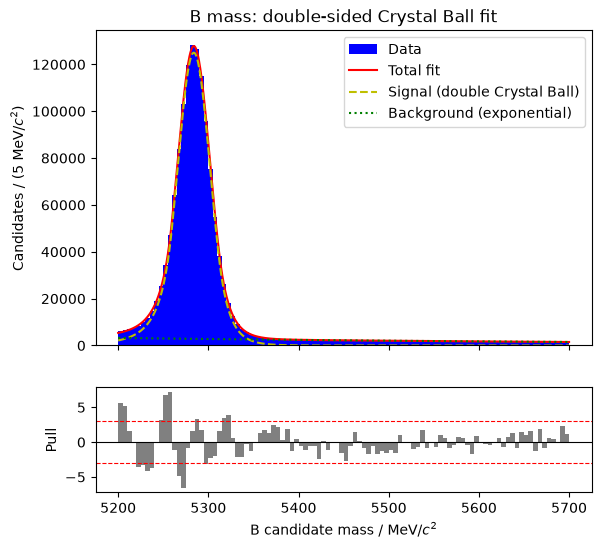

In [64]:
#Double-sided Crystal Ball for the B peak plus an exponential for the background
b_cb_space = zfit.Space('B invariant mass', (5200, 5700))

b_cb_mean   = zfit.Parameter('b_cb_mean',   5280, 5200, 5400)
b_cb_sigma  = zfit.Parameter('b_cb_sigma',  18,   1,    100)
b_cb_alphaL = zfit.Parameter('b_cb_alphaL', 1.5,  0.1,  10)
b_cb_nL     = zfit.Parameter('b_cb_nL',     3,    0.5,  100)
b_cb_alphaR = zfit.Parameter('b_cb_alphaR', 1.5,  0.1,  10)
b_cb_nR     = zfit.Parameter('b_cb_nR',     3,    0.5,  100)
b_cb_signalYield = zfit.Parameter('b_cb_signalYield', 3e5, 0, 1e7)

b_cb_signalPDF = zfit.pdf.DoubleCB(obs=b_cb_space, mu=b_cb_mean, sigma=b_cb_sigma,
                                   alphal=b_cb_alphaL, nl=b_cb_nL, alphar=b_cb_alphaR, nr=b_cb_nR,
                                   extended=b_cb_signalYield)

b_cb_exponent        = zfit.Parameter('b_cb_exponent', -0.003, -0.1, 0.1)
b_cb_backgroundYield = zfit.Parameter('b_cb_backgroundYield', 5e4, 0, 1e7)

b_cb_backgroundPDF = zfit.pdf.Exponential(obs=b_cb_space, lam=b_cb_exponent, extended=b_cb_backgroundYield)

b_cb_totalPDF = zfit.pdf.SumPDF(pdfs=[b_cb_signalPDF, b_cb_backgroundPDF])

result_b_cb = fit_and_plot(b_mass, b_cb_totalPDF,
                           components={'Signal (double Crystal Ball)': b_cb_signalPDF, 'Background (exponential)': b_cb_backgroundPDF},
                           xlabel=r'B candidate mass / MeV/$c^2$', title='B mass: double-sided Crystal Ball fit', show_pulls=True)

b_cb_mu_fit        = result_b_cb.params[b_cb_mean]['value']
b_cb_sigma_fit     = result_b_cb.params[b_cb_sigma]['value']
b_cb_sig_yield_fit = result_b_cb.params[b_cb_signalYield]['value']

**Something else under the high-mass tail: B⁺ → J/ψ π⁺.** If a pion is mistaken for a kaon, it is given the kaon mass, which is too heavy, so the B mass comes out about 50 MeV too high.
The check below takes J/ψ candidates sitting just *above* the B peak (5320–5420 MeV), gives the "kaon" the pion mass instead, and recomputes the B mass. If they are really B⁺ → J/ψ π⁺, they pile up at the B mass (5279 MeV).
The double-sided Crystal Ball's high-mass tail partly absorbs these events, so the signal yield above includes some J/ψ π decays. To count B → J/ψ K properly, this needs its own component in the fit (or a particle-ID cut on the kaon).

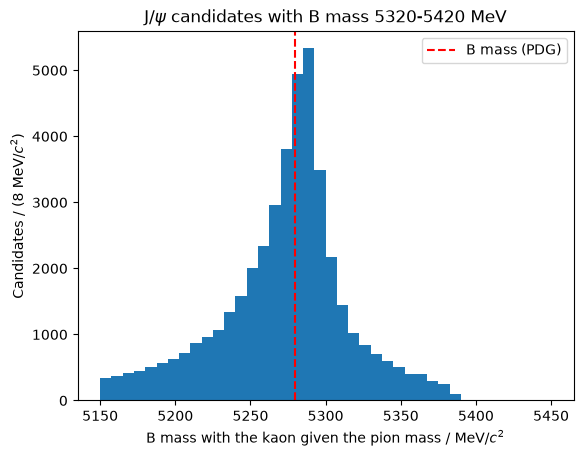

In [65]:
#Recompute the B mass with the kaon given the pion mass, for J/psi candidates just above the B peak
above_peak = (abs(dimuon_mass - M_JPSI) < 45) & (b_mass > 5320) & (b_mass < 5420)
check = data[above_peak]

kaon_as_pion_energy = track_energy(check, 'Kaon', M_PION)
total_energy = kaon_as_pion_energy + check['Same-sign muon 4-momentum energy component'] + check['Opposite-sign muon 4-momentum energy component']
total_momentum_sq = sum((check[f'Kaon 4-momentum {c} component'] + check[f'Same-sign muon 4-momentum {c} component']
                         + check[f'Opposite-sign muon 4-momentum {c} component'])**2 for c in 'xyz')
b_mass_kaon_as_pion = np.sqrt(total_energy**2 - total_momentum_sq)

plt.axvline(5279.3, color='red', linestyle='--', label='B mass (PDG)')
plt.legend()
plot_mass(b_mass_kaon_as_pion, r'B mass with the kaon given the pion mass / MeV/$c^2$', bins=40, range=(5150, 5450),
          title=r'J/$\psi$ candidates with B mass 5320-5420 MeV')

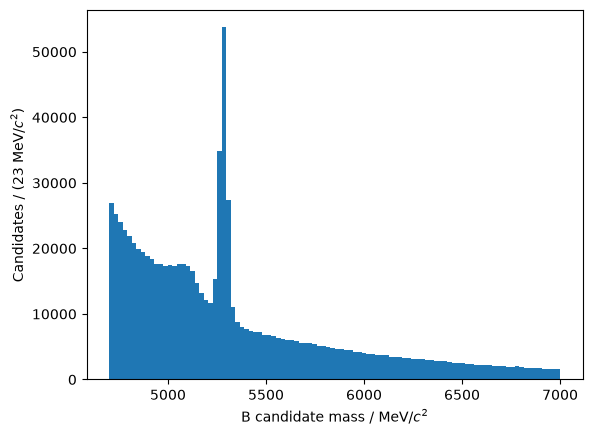

In [66]:
#Most of the real B mesons are actually B -> J/psi K decays. The J/psi is a charm-anticharm meson which decays to our two muons, and
#so, the dimuon system will have a mass consistent with the J/psi meson, 3097 MeV. If we remove these we get

not_jpsi = abs(dimuon_mass - M_JPSI) > 100

plot_mass(b_mass[not_jpsi], r'B candidate mass / MeV/$c^2$')

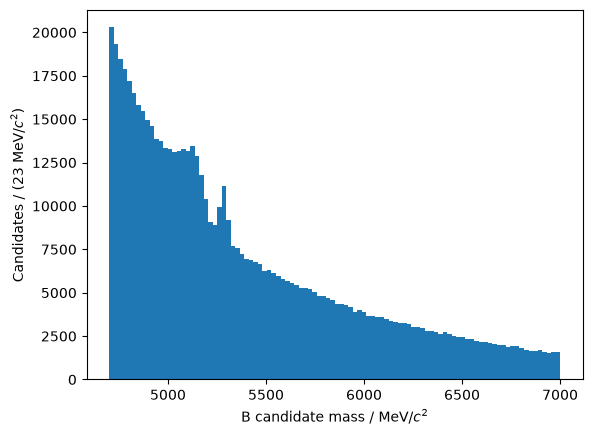

In [67]:
#Now most of what's remaining are actually B -> psi(2S) K decays. The psi(2S) is an excited state of the J/psi.
#It can also decay to our two muons, but now the dimuon system will have a mass consistent with the psi(2S) meson, 3686 MeV.
#If we also remove these, we'll see how much work we've got to do

not_psi2s = abs(dimuon_mass - M_PSI2S) > 100

plot_mass(b_mass[not_jpsi & not_psi2s], r'B candidate mass / MeV/$c^2$')

## Task 2: Dimuon mass spectrum

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.dist_tfp.Gauss'>  params=[jpsi_mean, jpsi_sigma]] data=[<zfit.Data: Data obs=('dimuon-system invariant mass',) shape=(2064472, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.2e-06 │        8558769.87 | -1551455 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                value  (rounded)        hesse    at limit
----------------  ------------------  -----------  ----------
jpsi_signalYield         2.06447e+06  +/- 1.4e+03       False
jpsi_mean                     3099.3  +/-   0.011       False
jpsi_sigma                   15.4055  +/-  0.0079       False

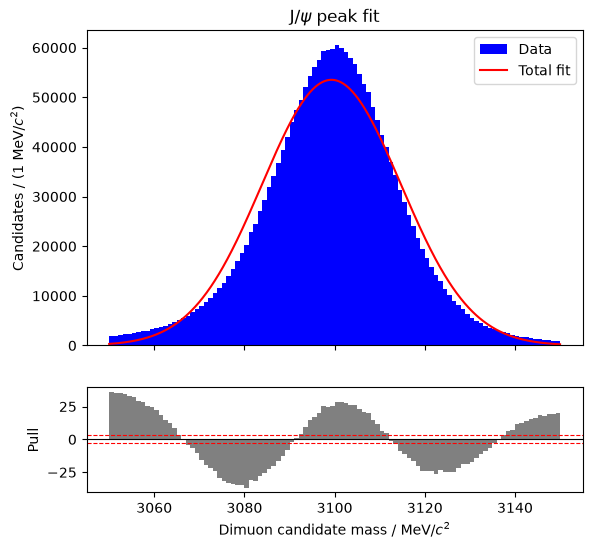

In [68]:
# Fit the J/psi peak and obtain a sigma to justify the width of exclusion
jpsi_space = zfit.Space('dimuon-system invariant mass', (3050, 3150))

jpsi_mean  = zfit.Parameter('jpsi_mean', 3102, 2700, 3200)
jpsi_sigma = zfit.Parameter('jpsi_sigma', 12,    5,  100)
jpsi_signalYield = zfit.Parameter('jpsi_signalYield', 5e5, 0, 1e7)

jpsi_PDF = zfit.pdf.Gauss(obs=jpsi_space, mu=jpsi_mean, sigma=jpsi_sigma, extended=jpsi_signalYield)

result_jpsi = fit_and_plot(dimuon_mass, jpsi_PDF, xlabel=r'Dimuon candidate mass / MeV/$c^2$', title=r'J/$\psi$ peak fit', show_pulls=True)

jpsi_mu_fit         = result_jpsi.params[jpsi_mean]['value']
jpsi_sigma_fit      = result_jpsi.params[jpsi_sigma]['value']
jpsi_sig_yield_fit  = result_jpsi.params[jpsi_signalYield]['value']

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_49, Composed_autoparam_50]] data=[<zfit.Data: Data obs=('dimuon-system invariant mass',) shape=(2167126, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00056 │        9465579.09 | -1195376 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                       value  (rounded)        hesse    at limit
-----------------------  ------------------  -----------  ----------
jpsi_cb_signalYield             2.08167e+06  +/- 1.6e+03       False
jpsi_cb_backgroundYield             85449.2  +/- 7.3e+02       False
jpsi_cb_me

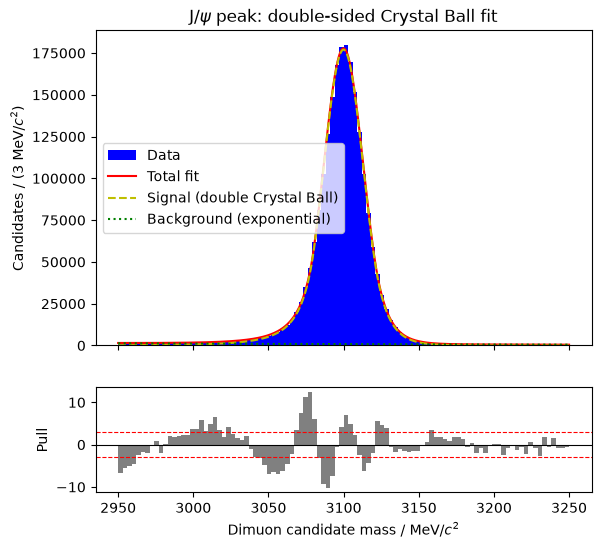

In [69]:
#Double-sided Crystal Ball for the J/psi peak plus an exponential for the background under it.
#A wider range than the Gaussian fit, so the tails and the background are included.
jpsi_cb_space = zfit.Space('dimuon-system invariant mass', (2950, 3250))

jpsi_cb_mean   = zfit.Parameter('jpsi_cb_mean',   3097, 3050, 3150)
jpsi_cb_sigma  = zfit.Parameter('jpsi_cb_sigma',  14,   1,    100)
jpsi_cb_alphaL = zfit.Parameter('jpsi_cb_alphaL', 1.5,  0.1,  10)
jpsi_cb_nL     = zfit.Parameter('jpsi_cb_nL',     3,    0.5,  100)
jpsi_cb_alphaR = zfit.Parameter('jpsi_cb_alphaR', 1.5,  0.1,  10)
jpsi_cb_nR     = zfit.Parameter('jpsi_cb_nR',     3,    0.5,  100)
jpsi_cb_signalYield = zfit.Parameter('jpsi_cb_signalYield', 6e5, 0, 1e7)

jpsi_cb_signalPDF = zfit.pdf.DoubleCB(obs=jpsi_cb_space, mu=jpsi_cb_mean, sigma=jpsi_cb_sigma,
                                      alphal=jpsi_cb_alphaL, nl=jpsi_cb_nL, alphar=jpsi_cb_alphaR, nr=jpsi_cb_nR,
                                      extended=jpsi_cb_signalYield)

jpsi_cb_exponent        = zfit.Parameter('jpsi_cb_exponent', -0.003, -0.1, 0.1)
jpsi_cb_backgroundYield = zfit.Parameter('jpsi_cb_backgroundYield', 3e4, 0, 1e7)

jpsi_cb_backgroundPDF = zfit.pdf.Exponential(obs=jpsi_cb_space, lam=jpsi_cb_exponent, extended=jpsi_cb_backgroundYield)

jpsi_cb_totalPDF = zfit.pdf.SumPDF(pdfs=[jpsi_cb_signalPDF, jpsi_cb_backgroundPDF])

result_jpsi_cb = fit_and_plot(dimuon_mass, jpsi_cb_totalPDF,
                              components={'Signal (double Crystal Ball)': jpsi_cb_signalPDF, 'Background (exponential)': jpsi_cb_backgroundPDF},
                              xlabel=r'Dimuon candidate mass / MeV/$c^2$', title=r'J/$\psi$ peak: double-sided Crystal Ball fit', show_pulls=True)

jpsi_cb_mu_fit        = result_jpsi_cb.params[jpsi_cb_mean]['value']
jpsi_cb_sigma_fit     = result_jpsi_cb.params[jpsi_cb_sigma]['value']
jpsi_cb_sig_yield_fit = result_jpsi_cb.params[jpsi_cb_signalYield]['value']

For the ψ(2S) a **single** Crystal Ball (low-mass tail only) is enough: the pulls already scatter within about ±3.
There are about 12× fewer ψ(2S) than J/ψ, so small differences in the tail shape can't be seen. We use the simplest shape that describes the data.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_52, Composed_autoparam_53]] data=[<zfit.Data: Data obs=('dimuon-system invariant mass',) shape=(212954, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 3.7e-05 │       1025446.87 | -134523.3 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                        value  (rounded)        hesse    at limit
------------------------  ------------------  -----------  ----------
psi2s_cb_signalYield                  166602  +/- 5.3e+02       False
psi2s_cb_backgroundYield             46352.3  +/-   4e+02       False
psi2s_c

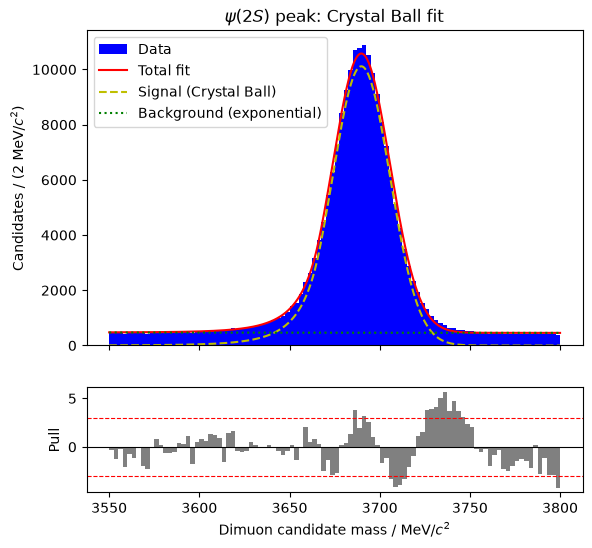

In [70]:
#Single Crystal Ball for the psi(2S) peak plus an exponential for the background under it
psi2s_cb_space = zfit.Space('dimuon-system invariant mass', (3550, 3800))

psi2s_cb_mean  = zfit.Parameter('psi2s_cb_mean',  3686, 3650, 3720)
psi2s_cb_sigma = zfit.Parameter('psi2s_cb_sigma', 17,   1,    100)
psi2s_cb_alpha = zfit.Parameter('psi2s_cb_alpha', 1.5,  0.1,  10)
psi2s_cb_n     = zfit.Parameter('psi2s_cb_n',     3,    0.5,  100)
psi2s_cb_signalYield = zfit.Parameter('psi2s_cb_signalYield', 3e4, 0, 1e7)

psi2s_cb_signalPDF = zfit.pdf.CrystalBall(obs=psi2s_cb_space, mu=psi2s_cb_mean, sigma=psi2s_cb_sigma,
                                          alpha=psi2s_cb_alpha, n=psi2s_cb_n, extended=psi2s_cb_signalYield)

psi2s_cb_exponent        = zfit.Parameter('psi2s_cb_exponent', -0.003, -0.1, 0.1)
psi2s_cb_backgroundYield = zfit.Parameter('psi2s_cb_backgroundYield', 3e4, 0, 1e7)

psi2s_cb_backgroundPDF = zfit.pdf.Exponential(obs=psi2s_cb_space, lam=psi2s_cb_exponent, extended=psi2s_cb_backgroundYield)

psi2s_cb_totalPDF = zfit.pdf.SumPDF(pdfs=[psi2s_cb_signalPDF, psi2s_cb_backgroundPDF])

result_psi2s_cb = fit_and_plot(dimuon_mass, psi2s_cb_totalPDF,
                               components={'Signal (Crystal Ball)': psi2s_cb_signalPDF, 'Background (exponential)': psi2s_cb_backgroundPDF},
                               xlabel=r'Dimuon candidate mass / MeV/$c^2$', title=r'$\psi(2S)$ peak: Crystal Ball fit', show_pulls=True)

psi2s_cb_mu_fit        = result_psi2s_cb.params[psi2s_cb_mean]['value']
psi2s_cb_sigma_fit     = result_psi2s_cb.params[psi2s_cb_sigma]['value']
psi2s_cb_sig_yield_fit = result_psi2s_cb.params[psi2s_cb_signalYield]['value']

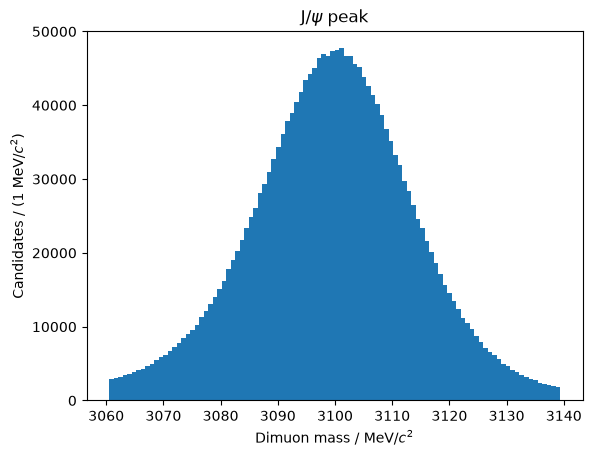

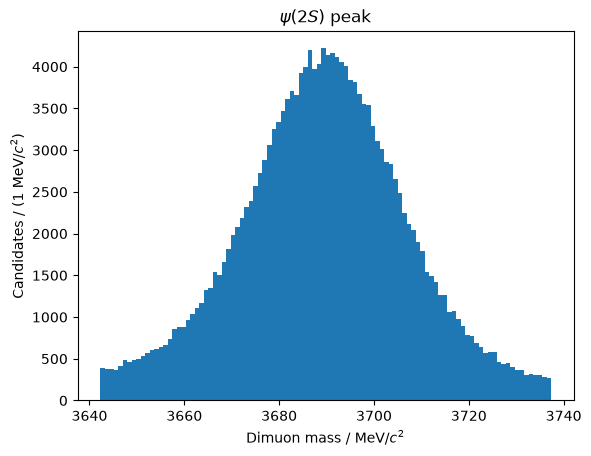

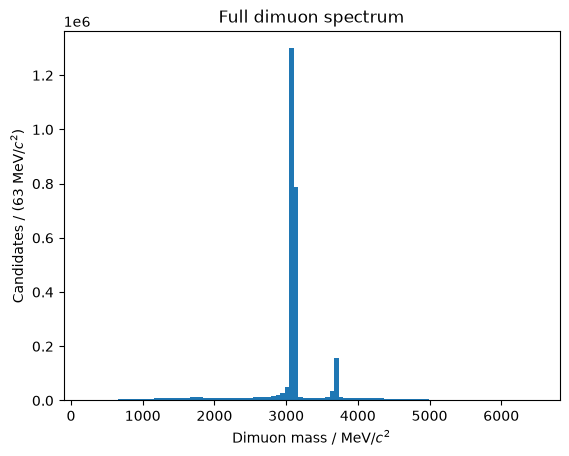

In [71]:
#J/psi and psi(2S) regions of the dimuon spectrum
#Each window is the fitted mean +- 3 sigma of the core, from the Crystal Ball fits above
#(True/False masks rather than copies of the data, to save memory)
jpsi_region  = abs(dimuon_mass - jpsi_cb_mu_fit)  < 3*jpsi_cb_sigma_fit
psi2s_region = abs(dimuon_mass - psi2s_cb_mu_fit) < 3*psi2s_cb_sigma_fit

plot_mass(dimuon_mass[jpsi_region],  r'Dimuon mass / MeV/$c^2$', title=r'J/$\psi$ peak')
plot_mass(dimuon_mass[psi2s_region], r'Dimuon mass / MeV/$c^2$', title=r'$\psi(2S)$ peak')
plot_mass(dimuon_mass, r'Dimuon mass / MeV/$c^2$', title='Full dimuon spectrum')

## Task 3: Signal-like and background-like regions
### Signal-like data
Real data where **both** masses sit in their peaks: the dimuon mass near the J/ψ **and** the B mass near the B peak.
Cutting on the dimuon mass alone is not enough, because it keeps every B mass from 4700 to 7000 MeV. That includes a real J/ψ combined with a random kaon, and B decays with a missed particle (the bump below 5150 MeV).
With both cuts, almost everything left is real B⁺ → J/ψ K⁺. This has the same final-state particles as the rare decay, and the B flies and decays the same way, so it is a good stand-in for the signal we want.

In [72]:
def add_muon_features(df):
    #Combine the two muons so it doesn't matter which one is called "same-sign" (the labels mean different things in the same-sign files)
    df['Muon min impact parameter chi2'] = np.minimum(df['Same-sign muon impact parameter chi2 wrt primary vertex'],
                                                      df['Opposite-sign muon impact parameter chi2 wrt primary vertex'])
    df['Muon min transverse momentum']   = np.minimum(df['Same-sign muon magnitude of momentum transverse to beam'],
                                                      df['Opposite-sign muon magnitude of momentum transverse to beam'])
    return df

data = add_muon_features(data)
samesign_all = add_muon_features(samesign_all)


Signal-like candidates: 1066157


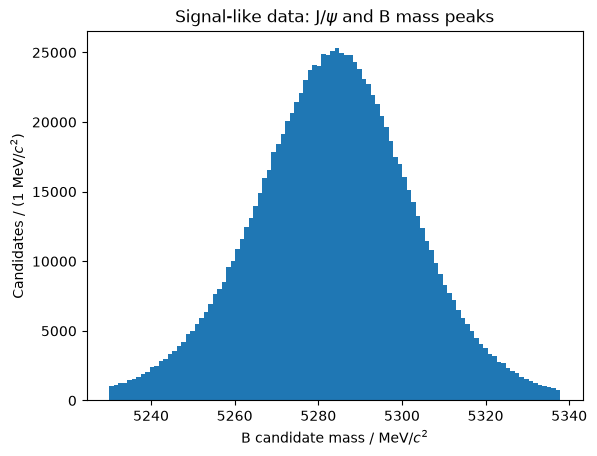

In [73]:
#Both masses within 3 sigma of their peaks (core widths from the Crystal Ball fits)
in_jpsi_peak = abs(dimuon_mass - jpsi_cb_mu_fit) < 3*jpsi_cb_sigma_fit
in_b_peak    = abs(b_mass - b_cb_mu_fit) < 3*b_cb_sigma_fit

signal_like = data[in_jpsi_peak & in_b_peak]

#Shuffle, so the train/test split later takes a random mix of events
signal_like = signal_like.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Signal-like candidates: {len(signal_like)}')
plot_mass(signal_like['B invariant mass'], r'B candidate mass / MeV/$c^2$', title=r'Signal-like data: J/$\psi$ and B mass peaks')

### Background-like data
Same-sign data: both muons have the same charge, so no real B decay can produce these candidates. Every one is a random combination of tracks.
We only use the same years as `data`. 2012 had a higher collision energy, so its events look slightly different; mixing years would let XGBoost learn "looks like 2012 = background" instead of real differences between signal and background.

Background-like candidates: 164104 (years: [np.int64(2011), np.int64(2012)])


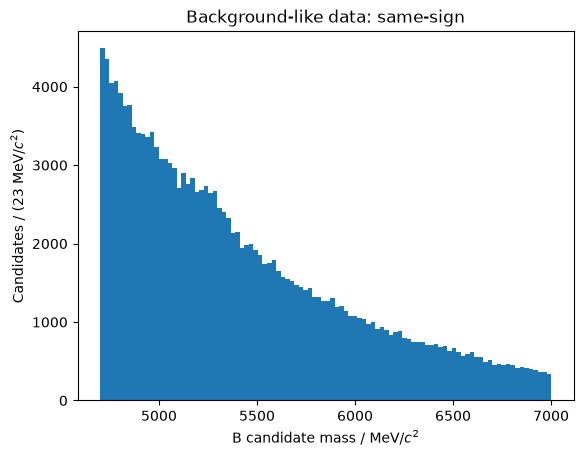

In [74]:
#Same-sign data from the same years as the signal sample
noise_like = samesign_all[samesign_all['Year'].isin(data['Year'].unique())]

#Shuffle: samesign_all is all of 2011 followed by all of 2012, so without this
#the test sample (the last 10%) could end up being all from one year
noise_like = noise_like.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Background-like candidates: {len(noise_like)} (years: {sorted(noise_like["Year"].unique())})')
plot_mass(noise_like['B invariant mass'], r'B candidate mass / MeV/$c^2$', title='Background-like data: same-sign')

### Identify how features vary between datasets

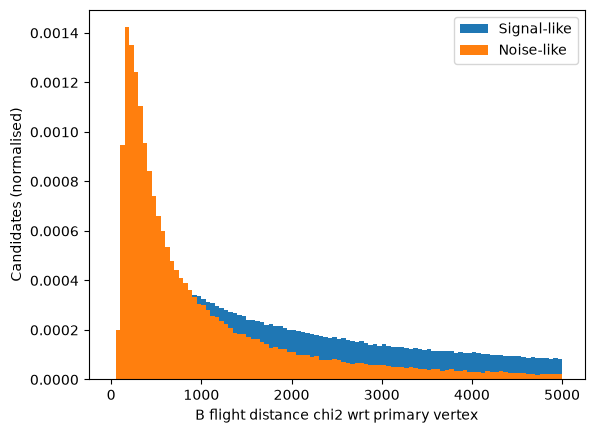

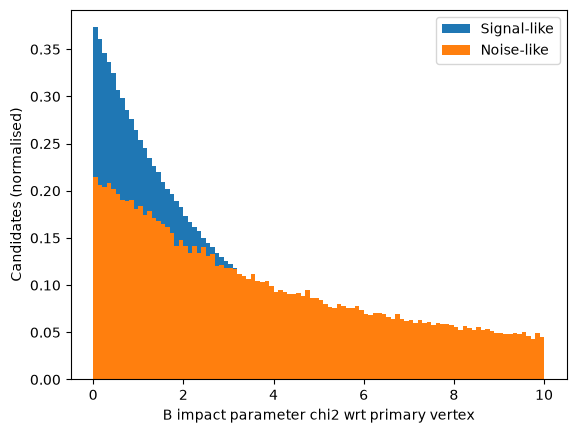

In [75]:
#(variable, plot range)
compare_variables = [
    ('B flight distance chi2 wrt primary vertex',  (0, 5000)),
    ('B impact parameter chi2 wrt primary vertex', (0, 10)),
]

for variable, plot_range in compare_variables:
    plt.hist(signal_like[variable], bins=100, range=plot_range, label='Signal-like', density=True)
    plt.hist(noise_like[variable],  bins=100, range=plot_range, label='Noise-like',  density=True)
    plt.xlabel(variable)
    plt.ylabel('Candidates (normalised)')
    plt.legend()
    plt.show()

### Choosing variables for XGBoost
 1. Initial shortlist: What could be useful

In [76]:
shortlist = [
    #B candidate
    'B decay vertex fit chi2',
    'B impact parameter wrt primary vertex',
    'B impact parameter chi2 wrt primary vertex',
    'B flight distance wrt primary vertex',
    'B flight distance chi2 wrt primary vertex',
    'B cos(angle) between line-of-flight and momentum',
    'B lifetime',
    'B magnitude of momentum transverse to beam',
    'B magnitude of momentum',
    #muon pair
    'dimuon-system decay vertex fit chi2',
    'dimuon-system impact parameter chi2 wrt primary vertex',
    'dimuon-system flight distance wrt B-decay vertex',
    'dimuon-system flight distance chi2 wrt B-decay vertex',
    'dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum',
    #tracks
    'Kaon impact parameter chi2 wrt primary vertex',
    'Kaon magnitude of momentum transverse to beam',
    'Muon min impact parameter chi2',
    'Muon min transverse momentum',
    #isolation
    'Isolation: B vertex delta chi2 adding one extra track (best fit)',
    'Isolation: B vertex delta chi2 adding two extra tracks (best fits)',
    'Isolation: B vertex number of well fitting additional tracks',
    'Isolation: ML output of best fitting extra track',
    'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
    'Isolation: Charged cone number of particles contained',
    'Isolation: Neutral cone ratio of B momentum and B+cone momentum all in transverse plane',
    'Isolation: Neutral cone number of particles containted',
]


 2. Overlay plots for each variable

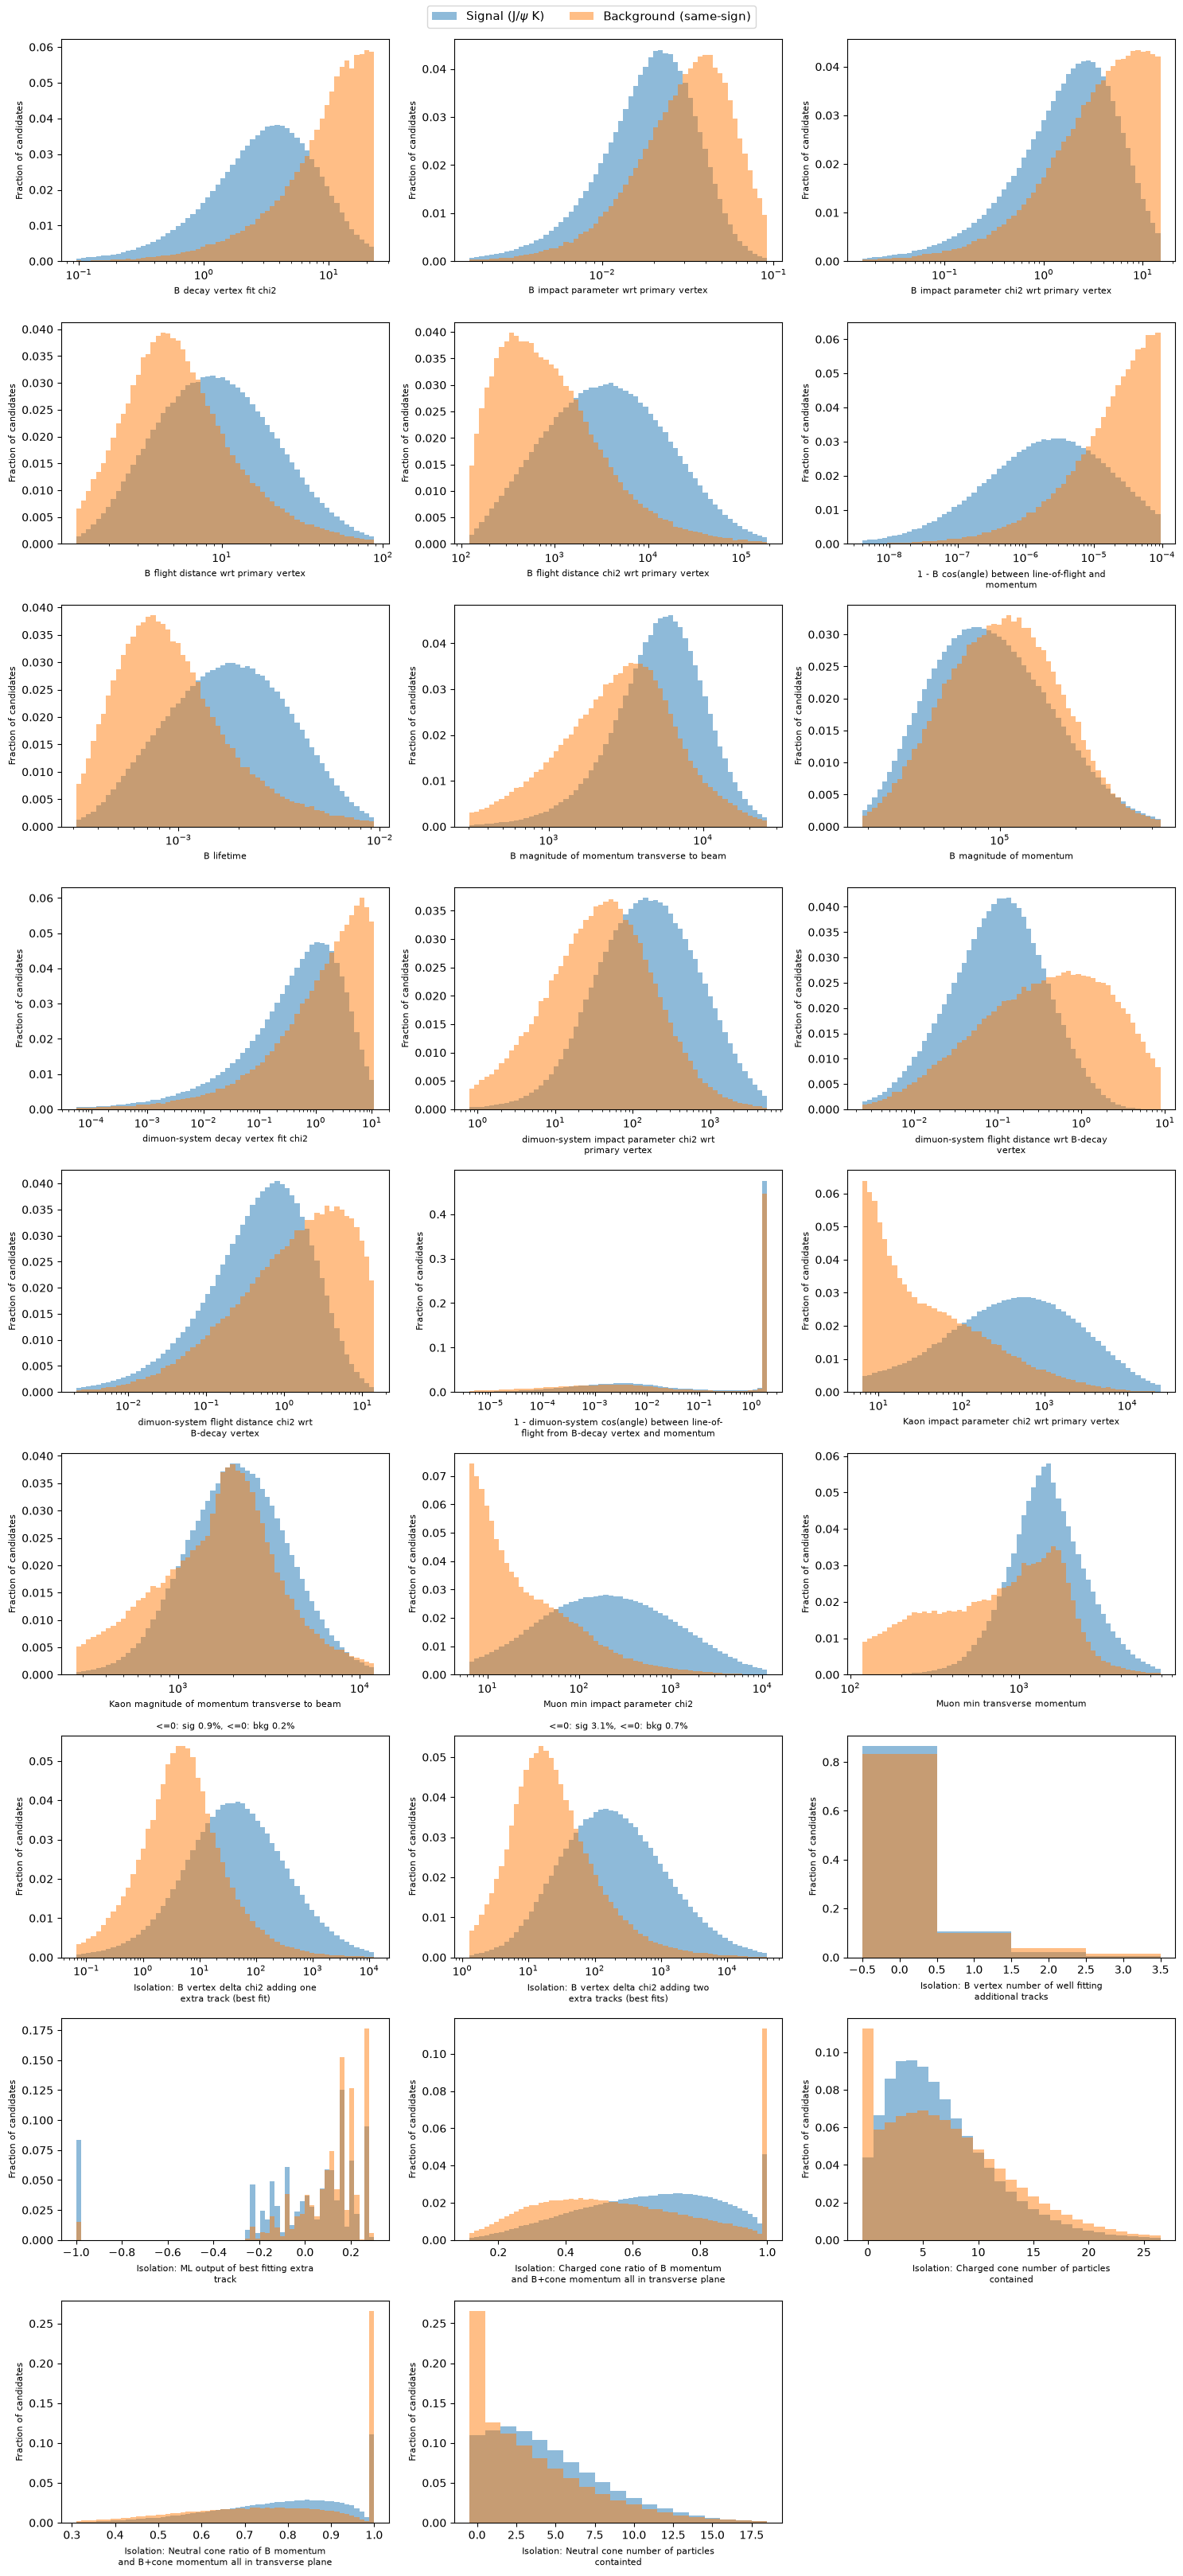

In [77]:
#Step 2: overlay signal (J/psi K) and background (same-sign) for every variable in the shortlist.
#Each histogram is normalised so its bars add up to 1: we compare the SHAPES, not the numbers of events.
#If the two shapes are different, the variable can help tell signal from background.
#
#chi2 variables (and those in log_also) have very long tails, so they get a log x-axis.
#Values <= 0 can't go on a log axis (the isolation variables use -1 to mean "nothing found"),
#so they are left out of the plot and the fraction of them is written above it instead.
#The plot range also leaves out the most extreme 0.5% on each side, so the tails don't squash the plot.

import textwrap
from matplotlib.ticker import NullFormatter

#Other long-tailed variables that are easier to read on a log axis
log_also = [
    'B impact parameter wrt primary vertex',
    'B flight distance wrt primary vertex',
    'B lifetime',
    'B magnitude of momentum transverse to beam',
    'B magnitude of momentum',
    'dimuon-system flight distance wrt B-decay vertex',
    'Kaon magnitude of momentum transverse to beam',
    'Muon min transverse momentum',
]

def overlay(ax, variable, signal, background, bins=60):
    sig = signal[variable].to_numpy(dtype=float)
    bkg = background[variable].to_numpy(dtype=float)
    notes = []

    #Missing values
    for name, values in (('sig', sig), ('bkg', bkg)):
        if np.isnan(values).mean() >= 0.001:
            notes.append(f'missing: {name} {np.isnan(values).mean():.1%}')
    sig, bkg = sig[~np.isnan(sig)], bkg[~np.isnan(bkg)]

    label = variable
    if 'cos(angle)' in variable:
        #cos is squeezed right up against 1 for everything, so plot 1 - cos on a log axis instead
        sig, bkg = 1 - sig, 1 - bkg
        label = '1 - ' + variable
        use_log = True
    else:
        use_log = 'chi2' in variable or variable in log_also

    if use_log:
        for name, values in (('sig', sig), ('bkg', bkg)):
            if (values <= 0).mean() >= 0.001:
                notes.append(f'<=0: {name} {(values <= 0).mean():.1%}')
        sig, bkg = sig[sig > 0], bkg[bkg > 0]
        lo, hi = np.percentile(np.concatenate([sig, bkg]), [0.5, 99.5])
        edges = np.logspace(np.log10(lo), np.log10(hi), bins + 1)
        ax.set_xscale('log')
        ax.xaxis.set_minor_formatter(NullFormatter())   #stop the small in-between ticks being labelled
    else:
        both = np.concatenate([sig, bkg])
        lo, hi = np.percentile(both, [0.5, 99.5])
        if np.all(both == np.round(both)) and hi - lo < 100:
            edges = np.arange(lo - 0.5, hi + 1.5)   #whole-number counts: one bin per value
        else:
            edges = np.linspace(lo, hi, bins + 1)

    ax.hist(sig, bins=edges, weights=np.full(len(sig), 1 / len(sig)), alpha=0.5, color='tab:blue', label=r'Signal (J/$\psi$ K)')
    ax.hist(bkg, bins=edges, weights=np.full(len(bkg), 1 / len(bkg)), alpha=0.5, color='tab:orange', label='Background (same-sign)')
    ax.set_xlabel(textwrap.fill(label, 45), fontsize=8)
    ax.set_ylabel('Fraction of candidates', fontsize=8)
    if notes:
        ax.set_title(', '.join(notes), fontsize=8)


n_cols = 3
n_rows = int(np.ceil(len(shortlist) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.6 * n_rows))

for ax, variable in zip(axes.flat, shortlist):
    overlay(ax, variable, signal_like, noise_like)
for ax in axes.flat[len(shortlist):]:
    ax.set_visible(False)   #hide the unused spaces in the last row

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.99))
plt.show()

Check PMCC of all variables with B mass and dimuon mass in *background* dataset - lower correlation is a check for good candidate variable to train XGBoost on.

3. AUC 'separation' score thing for each variable

In [78]:
from sklearn.metrics import roc_auc_score

scores = []
for var in shortlist:
    sig = signal_like[var].dropna()
    bkg = noise_like[var].dropna()
    y = np.r_[np.ones(len(sig)), np.zeros(len(bkg))]
    auc = roc_auc_score(y, np.r_[sig, bkg])
    scores.append((var, max(auc, 1 - auc)))   #1-auc in case background has the larger values
print(tabulate(sorted(scores, key=lambda s: -s[1]), headers=['Variable', 'Separation (AUC)']))


Variable                                                                                   Separation (AUC)
---------------------------------------------------------------------------------------  ------------------
Muon min impact parameter chi2                                                                     0.843555
Kaon impact parameter chi2 wrt primary vertex                                                      0.829274
B decay vertex fit chi2                                                                            0.804419
B cos(angle) between line-of-flight and momentum                                                   0.795841
Isolation: B vertex delta chi2 adding two extra tracks (best fits)                                 0.79449
Isolation: B vertex delta chi2 adding one extra track (best fit)                                   0.787246
B flight distance chi2 wrt primary vertex                                                          0.765711
B lifetime                   

4. Safety check: correlation with the B mass and the dimuon mass, in *background* data (same-sign)

We use the same-sign data from **all** years here: it is only a safety check, so more events is better, and whether a variable is tied to a mass shouldn't depend on the year.

Two kinds of correlation are shown:
- **Pearson** (PMCC) only measures straight-line relationships, and the long tails of the χ² variables can hide a relationship completely.
- **Spearman** (rank correlation) replaces each value by its rank (1st, 2nd, 3rd...) before correlating, so long tails don't matter and any "goes up together" relationship is caught.

Spearman is the one we use for decisions. Example: `dimuon-system flight distance wrt B-decay vertex` has Pearson 0.09 with the dimuon mass but Spearman 0.65.

In [79]:
#Correlation of every shortlisted variable with the B mass, in background data (same-sign)
b_mass_background = samesign_all['B invariant mass']

corr_b_mass = {}
for var in shortlist:
    pearson  = abs(samesign_all[var].corr(b_mass_background))
    spearman = abs(samesign_all[var].corr(b_mass_background, method='spearman'))
    corr_b_mass[var] = (pearson, spearman)

rows = sorted(((var, p, s) for var, (p, s) in corr_b_mass.items()), key=lambda r: r[2])
print(tabulate(rows, headers=['Variable', 'Pearson', 'Spearman'], floatfmt='.3f'))

Variable                                                                                   Pearson    Spearman
---------------------------------------------------------------------------------------  ---------  ----------
B flight distance chi2 wrt primary vertex                                                    0.011       0.002
Isolation: B vertex number of well fitting additional tracks                                 0.006       0.016
dimuon-system flight distance chi2 wrt B-decay vertex                                        0.011       0.025
dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum             0.028       0.031
Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane      0.037       0.035
dimuon-system decay vertex fit chi2                                                          0.035       0.035
dimuon-system flight distance wrt B-decay vertex                                             0.005       0.036
B

In [80]:
#Correlation of every shortlisted variable with the dimuon mass, in background data (same-sign)
dimuon_mass_background = samesign_all['dimuon-system invariant mass']

corr_dimuon_mass = {}
for var in shortlist:
    pearson  = abs(samesign_all[var].corr(dimuon_mass_background))
    spearman = abs(samesign_all[var].corr(dimuon_mass_background, method='spearman'))
    corr_dimuon_mass[var] = (pearson, spearman)

rows = sorted(((var, p, s) for var, (p, s) in corr_dimuon_mass.items()), key=lambda r: r[2])
print(tabulate(rows, headers=['Variable', 'Pearson', 'Spearman'], floatfmt='.3f'))

Variable                                                                                   Pearson    Spearman
---------------------------------------------------------------------------------------  ---------  ----------
B decay vertex fit chi2                                                                      0.025       0.013
Isolation: B vertex number of well fitting additional tracks                                 0.029       0.016
B lifetime                                                                                   0.004       0.019
Isolation: B vertex delta chi2 adding one extra track (best fit)                             0.002       0.022
Isolation: B vertex delta chi2 adding two extra tracks (best fits)                           0.004       0.023
B impact parameter chi2 wrt primary vertex                                                   0.029       0.031
Isolation: Charged cone number of particles contained                                        0.021       0.043
B

5. Does the **signal** change with the dimuon mass?

The background check above only tells us whether a variable *carries* dimuon-mass information. What we really need to know is whether real signal looks different at different dimuon masses, because we train on J/ψ K (dimuon mass 3.1 GeV) but want the rare decay at *all* dimuon masses.

Our data contains real signal at two different dimuon masses: B → J/ψ K and B → ψ(2S) K. Both samples are clean (B mass and dimuon mass both in their peaks), so we compare them with the same AUC score as step 3:
- **AUC ≈ 0.5**: the variable looks the same for both, so it doesn't depend on the dimuon mass.
- **AUC well above 0.5**: real signal changes with dimuon mass. The rare decay covers an even wider range of dimuon masses, so it would change even more.

(The simulation can't be used for this: it says every variable looks the same at all dimuon masses, but the real data shows clear differences. The simulation is too simple to show this effect.)

In [81]:
#Clean B -> psi(2S) K sample: dimuon mass in the psi(2S) peak and B mass in the B peak
in_psi2s_peak = abs(dimuon_mass - psi2s_cb_mu_fit) < 3*psi2s_cb_sigma_fit
psi2s_signal_like = data[in_psi2s_peak & in_b_peak]
print(f'B -> J/psi K candidates: {len(signal_like)}, B -> psi(2S) K candidates: {len(psi2s_signal_like)}')

#AUC between the two signals for every shortlisted variable (0.5 = no difference)
signal_dimuon_auc = {}
for var in shortlist:
    jpsi_values  = signal_like[var].dropna()
    psi2s_values = psi2s_signal_like[var].dropna()
    y = np.r_[np.ones(len(jpsi_values)), np.zeros(len(psi2s_values))]
    auc = roc_auc_score(y, np.r_[jpsi_values, psi2s_values])
    signal_dimuon_auc[var] = max(auc, 1 - auc)

rows = sorted(signal_dimuon_auc.items(), key=lambda r: r[1])
print(tabulate(rows, headers=['Variable', 'AUC J/psi K vs psi(2S) K'], floatfmt='.3f'))

B -> J/psi K candidates: 1066157, B -> psi(2S) K candidates: 92428
Variable                                                                                   AUC J/psi K vs psi(2S) K
---------------------------------------------------------------------------------------  --------------------------
B impact parameter chi2 wrt primary vertex                                                                    0.500
dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum                              0.501
dimuon-system decay vertex fit chi2                                                                           0.501
Isolation: B vertex number of well fitting additional tracks                                                  0.501
Isolation: ML output of best fitting extra track                                                              0.502
Isolation: Neutral cone ratio of B momentum and B+cone momentum all in transverse plane                       0.503
B lif

### New shortlist from the AUC and safety checks
A variable is kept only if it passes all three tests:
1. **It separates signal from background:** AUC above 0.65 (step 3).
2. **It is safe for the B mass:** Spearman correlation with B mass in background below 0.15.
   A weak, smooth correlation can only tilt the background a little, and the background's slope is a free parameter in the fit, so that is absorbed. What we must avoid is a cut that *creates a bump*, and we check that directly after training (step 9).
3. **It is safe for the dimuon mass:** dropped if it **both** carries dimuon-mass information in background (Spearman above 0.2) **and** changes for real signal between J/ψ K and ψ(2S) K (AUC above 0.55).
   Together these mean XGBoost could learn "looks like a J/ψ = signal" and throw away real rare decays at other dimuon masses. If only one of the two is true, the risk is small.

In [82]:
# thresholds used
min_auc                 = 0.65
max_corr_b_mass         = 0.15
max_corr_dimuon_mass    = 0.20
max_signal_dimuon_auc   = 0.55

auc_of = dict(scores)
rows = []
shortlist_safe = []
for var in sorted(shortlist, key=lambda v: -auc_of[v]):
    reasons = []
    if auc_of[var] <= min_auc:
        reasons.append('weak separation')
    if corr_b_mass[var][1] >= max_corr_b_mass:
        reasons.append('tied to B mass')
    if corr_dimuon_mass[var][1] >= max_corr_dimuon_mass and signal_dimuon_auc[var] >= max_signal_dimuon_auc:
        reasons.append('tied to dimuon mass')

    if not reasons:
        shortlist_safe.append(var)
    rows.append((var, auc_of[var], corr_b_mass[var][1], corr_dimuon_mass[var][1], signal_dimuon_auc[var],
                 'KEEP' if not reasons else 'drop: ' + ', '.join(reasons)))

print(tabulate(rows, headers=['Variable', 'AUC (sig vs bkg)', 'Spearman B mass', 'Spearman dimuon mass',
                              'AUC J/psi vs psi(2S)', 'Decision'], floatfmt='.3f'))
print(f'\n{len(shortlist_safe)} of {len(shortlist)} variables kept')

Variable                                                                                   AUC (sig vs bkg)    Spearman B mass    Spearman dimuon mass    AUC J/psi vs psi(2S)  Decision
---------------------------------------------------------------------------------------  ------------------  -----------------  ----------------------  ----------------------  ------------------------------------------
Muon min impact parameter chi2                                                                        0.844              0.077                   0.297                   0.522  KEEP
Kaon impact parameter chi2 wrt primary vertex                                                         0.829              0.131                   0.140                   0.558  KEEP
B decay vertex fit chi2                                                                               0.804              0.082                   0.013                   0.505  KEEP
B cos(angle) between line-of-flight and momentum     

## Task 4: Selection with XGBoost
### Training

We split each sample (signal and background) into three parts:
- **Training (70%)**: what XGBoost learns from.
- **Validation (15%)**: used to decide when to stop adding trees, and to compare different variable lists when pruning.
- **Test (15%)**: never used to make any choice. Only used at the end for the ROC curve, the overtraining check and the efficiency of the cut. Because nothing was tuned on it, it gives an honest measure of how well the model works.

Before, early stopping used the test sample, so the test sample was helping to choose the model and its AUC came out slightly too good.

`train_bdt` uses gentle XGBoost settings (small trees, small learning steps, plenty of events in every branch, and each tree only sees a random 80% of the data). With the original settings (learning rate 0.3, depth 6), on 2011 data, the model memorised parts of the background training sample: it scored AUC 0.962 on its training events but only 0.947 on the test sample. The gentle settings give a *higher* test AUC (about 0.949) and much less overtraining (step 8). The cost is that each training takes about 30 s instead of 3 s, so the pruning in step 7 takes a few minutes.

In [83]:
import xgboost

def split_sample(df):
    #Both samples were shuffled when they were made, so taking slices gives random parts
    n = len(df)
    n_train, n_val = int(0.7*n), int(0.15*n)
    return df[:n_train], df[n_train:n_train + n_val], df[n_train + n_val:]

signal_train,     signal_val,     signal_test     = split_sample(signal_like)
background_train, background_val, background_test = split_sample(noise_like)

def make_xy(signal, background, variables):
    #Inputs (x) and labels (y: 1 = signal, 0 = background) for XGBoost
    x = pandas.concat([signal[variables], background[variables]], ignore_index=True)
    y = np.r_[np.ones(len(signal)), np.zeros(len(background))]
    return x, y

def train_bdt(variables):
    #Train XGBoost on the given variables. Returns the model and its AUC on the validation sample.
    x_train, y_train = make_xy(signal_train, background_train, variables)
    x_val,   y_val   = make_xy(signal_val,   background_val,   variables)
    #Gentle settings so the model can't memorise the (small) background training sample - see step 8
    bdt = xgboost.XGBClassifier(eval_metric='auc', early_stopping_rounds=50, n_estimators=3000,
                                learning_rate=0.05,      #small steps: each tree only corrects a little
                                max_depth=3,             #small trees: each one can only use a few variables at once
                                min_child_weight=100,    #every final branch must contain plenty of events
                                subsample=0.8,           #each tree sees a random 80% of the events...
                                colsample_bytree=0.8,    #...and a random 80% of the variables
                                random_state=42,         #so the random choices are the same every time we run it
                                importance_type='gain')
    bdt.fit(x_train, y_train, eval_set=[(x_val, y_val)], verbose=False)
    val_auc = roc_auc_score(y_val, bdt.predict_proba(x_val)[:, 1])
    return bdt, val_auc

print(f'Signal:     {len(signal_train)} train, {len(signal_val)} validation, {len(signal_test)} test')
print(f'Background: {len(background_train)} train, {len(background_val)} validation, {len(background_test)} test')

Signal:     746309 train, 159923 validation, 159925 test
Background: 114872 train, 24615 validation, 24617 test


6. Train on every variable in the safe shortlist and look at how much XGBoost uses each one.

"Importance" here is the *gain*: how much each variable improved the separation, summed over every time the model used it.
We also measure how noisy the validation AUC is, by recomputing it on many random resamples of the validation sample (a "bootstrap"). Any change in AUC smaller than this noise can't be told apart from chance.

In [84]:
full_bdt, full_auc = train_bdt(shortlist_safe)
print(f'Validation AUC with all {len(shortlist_safe)} variables: {full_auc:.4f}\n')

for var, imp in sorted(zip(shortlist_safe, full_bdt.feature_importances_), key=lambda x: -x[1]):
    print(f'{imp:.3f}  {var}')

#How noisy is the validation AUC? Recompute it on 200 random resamples of the validation sample
x_val, y_val = make_xy(signal_val, background_val, shortlist_safe)
val_prob = full_bdt.predict_proba(x_val)[:, 1]
rng = np.random.default_rng(1)
bootstrap_aucs = []
for _ in range(200):
    pick = rng.integers(0, len(y_val), len(y_val))
    bootstrap_aucs.append(roc_auc_score(y_val[pick], val_prob[pick]))
auc_uncertainty = np.std(bootstrap_aucs)
print(f'\nUncertainty on the validation AUC: {auc_uncertainty:.4f}')

Validation AUC with all 14 variables: 0.9562

0.277  Muon min impact parameter chi2
0.236  B decay vertex fit chi2
0.111  Kaon impact parameter chi2 wrt primary vertex
0.077  Isolation: B vertex delta chi2 adding two extra tracks (best fits)
0.075  B impact parameter wrt primary vertex
0.051  Isolation: B vertex delta chi2 adding one extra track (best fit)
0.043  B magnitude of momentum transverse to beam
0.043  B impact parameter chi2 wrt primary vertex
0.027  Isolation: ML output of best fitting extra track
0.024  B cos(angle) between line-of-flight and momentum
0.012  B flight distance chi2 wrt primary vertex
0.009  dimuon-system decay vertex fit chi2
0.008  B flight distance wrt primary vertex
0.005  B lifetime

Uncertainty on the validation AUC: 0.0008


7. Pruning: remove the least important variable, retrain, and see how much the validation AUC drops. Repeat all the way down to one variable.

We then keep the **smallest** list whose AUC is still within the AUC's uncertainty of the model with **all** the variables. Removing more than that would make the model measurably worse; keeping more adds variables that we can't show are helping.
(We compare with the all-variables model rather than the highest AUC in the table, because the highest value is usually the one that happened to fluctuate upwards.)
Pruning also deals with near-duplicates (e.g. `B lifetime` and `B flight distance chi2`): when two variables carry the same information, removing one barely changes the AUC.

In [ ]:
#Remove variables one at a time, weakest first. Stop as soon as a removal makes the validation AUC
#drop below (all-variables AUC - its uncertainty): removing even more after that only makes it worse.
threshold = full_auc - auc_uncertainty

current = list(shortlist_safe)
bdt = full_bdt
history = [(len(current), full_auc, '(none, all variables)', list(current))]

while len(current) > 1:
    weakest = current[int(np.argmin(bdt.feature_importances_))]
    trial = [v for v in current if v != weakest]
    trial_bdt, auc = train_bdt(trial)
    history.append((len(trial), auc, weakest, list(trial)))
    print(f'Removed {weakest} -> {len(trial)} variables, validation AUC {auc:.4f}', flush=True)
    if auc < threshold:
        print('AUC is now clearly worse, so we stop here and keep the previous list.')
        break
    current, bdt = trial, trial_bdt

print()
print(tabulate([(n, auc, removed) for n, auc, removed, _ in history],
               headers=['Variables', 'Validation AUC', 'Removed'], floatfmt='.4f'))

#Smallest list within the uncertainty of the all-variables AUC
chosen = min((h for h in history if h[1] >= threshold), key=lambda h: h[0])
training_variables = chosen[3]


KeyboardInterrupt: 

### Final model
Retrain on the chosen variables. The test sample is used here for the first time.

In [ ]:
model, val_auc = train_bdt(training_variables)

x_test, y_test = make_xy(signal_test, background_test, training_variables)
test_auc = roc_auc_score(y_test, model.predict_proba(x_test)[:, 1])
print(f'Validation AUC: {val_auc:.4f}, test AUC: {test_auc:.4f}')

Validation AUC: 0.9505, test AUC: 0.9487


### Results on the test sample

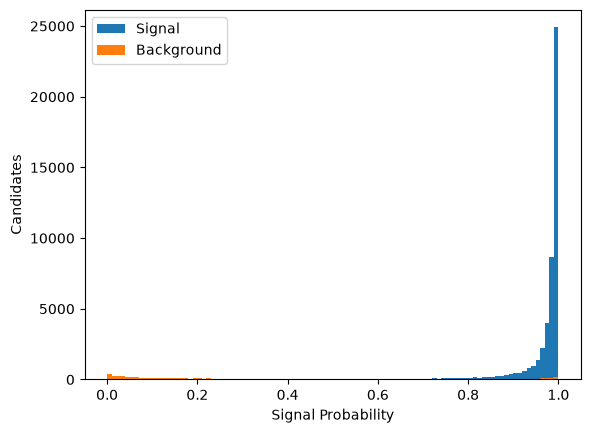

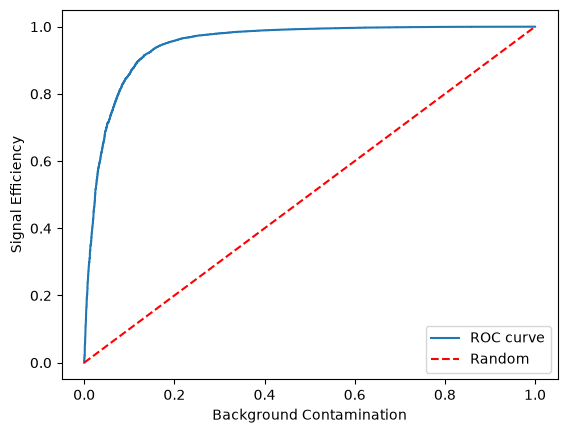

In [ ]:
from sklearn.metrics import roc_curve

test_prediction = model.predict_proba(x_test)

plt.hist([p[1] for p,cls in zip(test_prediction, y_test) if cls == 1], bins=100, label='Signal')
plt.hist([p[1] for p,cls in zip(test_prediction, y_test) if cls == 0], bins=100, label='Background')
plt.xlabel(r'Signal Probability')
plt.ylabel(r'Candidates')
plt.legend()
plt.show()

background_accepted, signal_accepted, probabilities_tested = roc_curve(y_test, test_prediction[:,1])
plt.plot(background_accepted, signal_accepted, label='ROC curve')
plt.plot([0,1], [0,1], color='red', linestyle='--', label = 'Random')
plt.xlabel(r'Background Contamination')
plt.ylabel(r'Signal Efficiency')
plt.legend()
plt.show()

8. Overtraining check

"Overtraining" means the model has memorised its training events instead of learning patterns that are true for all events. If so, it scores its own training events better than new events, and its performance on real data will be worse than it looks.

To check, we compare the model's output for **training** events (filled bars) and **test** events (points) that it has never seen, separately for signal and background. If there is no overtraining, the two match within their error bars.

We also compare the **train AUC with the test AUC**. The training value is always a little higher; a gap much bigger than the AUC's uncertainty means overtraining.

Train AUC: 0.9542, test AUC: 0.9487, difference: 0.0055 (AUC uncertainty is about 0.0015)


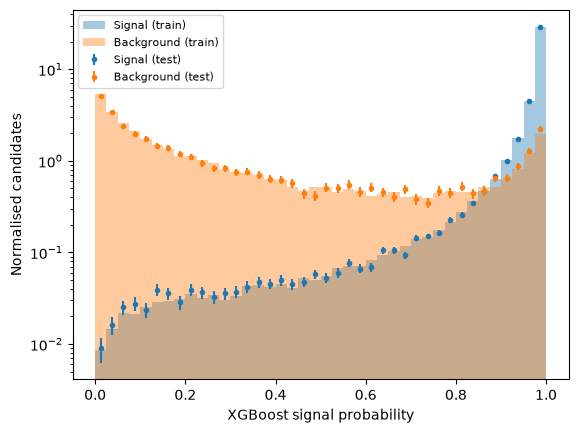

In [ ]:
#Model output for every training and test event
prob = {
    ('Signal', 'train'):     model.predict_proba(signal_train[training_variables])[:, 1],
    ('Signal', 'test'):      model.predict_proba(signal_test[training_variables])[:, 1],
    ('Background', 'train'): model.predict_proba(background_train[training_variables])[:, 1],
    ('Background', 'test'):  model.predict_proba(background_test[training_variables])[:, 1],
}

train_auc = roc_auc_score(np.r_[np.ones(len(prob['Signal', 'train'])), np.zeros(len(prob['Background', 'train']))],
                          np.r_[prob['Signal', 'train'], prob['Background', 'train']])
print(f'Train AUC: {train_auc:.4f}, test AUC: {test_auc:.4f}, difference: {train_auc - test_auc:.4f} '
      f'(AUC uncertainty is about {auc_uncertainty:.4f})')

edges = np.linspace(0, 1, 41)
centres = 0.5 * (edges[1:] + edges[:-1])
colours = {'Signal': 'tab:blue', 'Background': 'tab:orange'}

for kind in ('Signal', 'Background'):
    train, test = prob[kind, 'train'], prob[kind, 'test']

    #Training events as filled bars, normalised to area 1
    plt.hist(train, bins=edges, density=True, alpha=0.4, color=colours[kind], label=f'{kind} (train)')

    #Test events as points with error bars, normalised the same way
    counts, _ = np.histogram(test, bins=edges)
    scale = 1 / (len(test) * (edges[1] - edges[0]))
    plt.errorbar(centres, counts * scale, yerr=np.sqrt(counts) * scale, fmt='o', markersize=3,
                 color=colours[kind], label=f'{kind} (test)')

plt.yscale('log')   #log scale so the small tails in the middle are visible too
plt.xlabel('XGBoost signal probability')
plt.ylabel('Normalised candidates')
plt.legend(fontsize=8)
plt.show()

### Apply the selection to the full dataset

In [ ]:
#Signal probability for every candidate in the dataset
signal_probability = model.predict_proba(data[training_variables])[:, 1]

#threshold set at 0.99
passes_bdt = signal_probability > 0.99

## Task 5: K+ mu- two body system

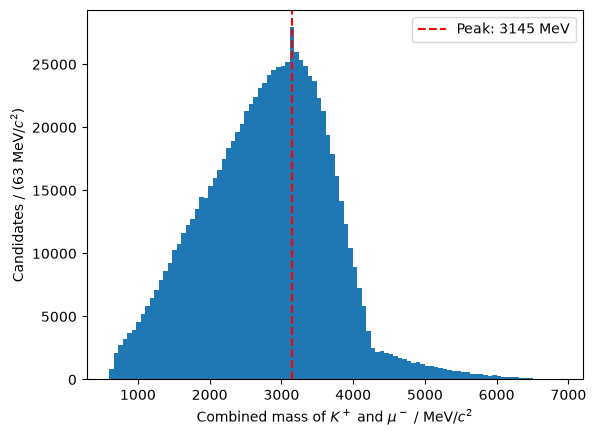

In [ ]:
#Using the energies stored in the data (the detector's own mass assignments)
kmu_mass = two_body_mass(data, 'Kaon', 'Opposite-sign muon')

plot_mass(kmu_mass, r'Combined mass of $K^+$ and $\mu^-$ / MeV/$c^2$', show_peak=True)

### Masses correct
Kaon given the kaon mass, muon given the muon mass.

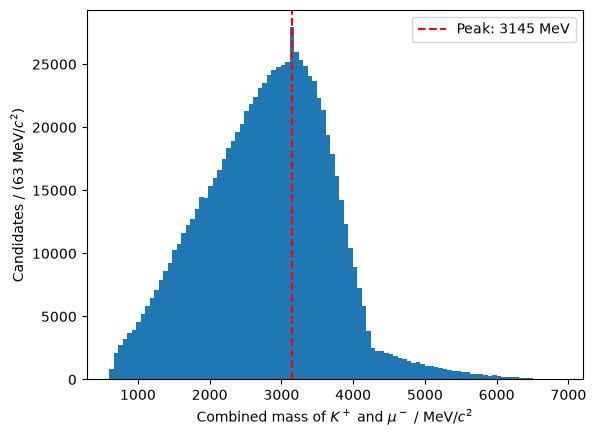

In [ ]:
kmu_mass_correct = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_MUON)

plot_mass(kmu_mass_correct, r'Combined mass of $K^+$ and $\mu^-$ / MeV/$c^2$', show_peak=True)

## Kaon mistaken for a muon (so muon has kaon mass)

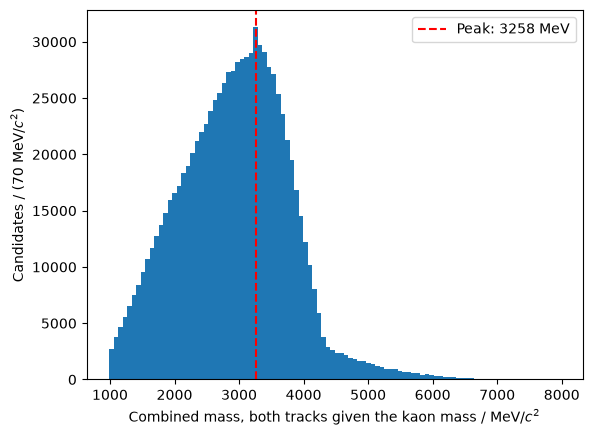

In [ ]:
kmu_mass_as_kk = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_KAON)

plot_mass(kmu_mass_as_kk, r'Combined mass, both tracks given the kaon mass / MeV/$c^2$', show_peak=True)

## Muon mistaken for a kaon (so kaon has muon mass)

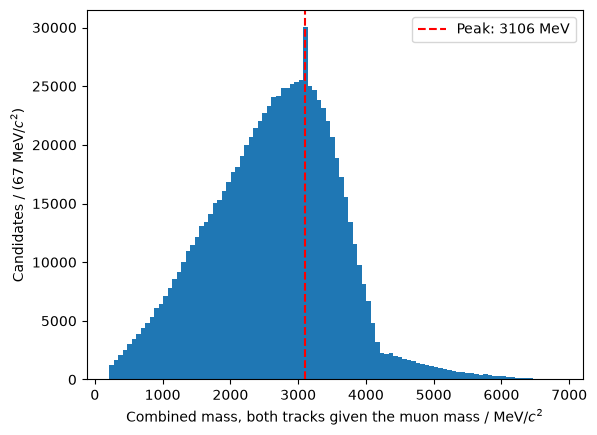

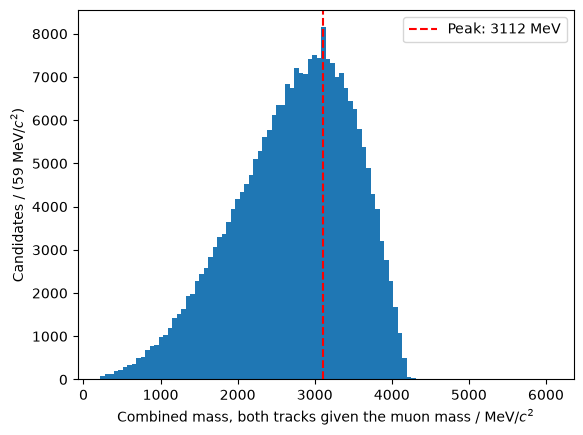

In [ ]:
kmu_mass_as_mumu = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_MUON, M_MUON)

#before the XGBoost selection
plot_mass(kmu_mass_as_mumu, r'Combined mass, both tracks given the muon mass / MeV/$c^2$', show_peak=True)

#after the XGBoost selection
plot_mass(kmu_mass_as_mumu[passes_bdt], r'Combined mass, both tracks given the muon mass / MeV/$c^2$', show_peak=True)

## Kill the peak

after the XGBoost algorithm is used to cut out the background noise the mode is exactly 3097. In general, the peak being close to 3000 MeV/c^2 seems to be a coincidence (from the research that I've done. So a peak within that region or so is normal.). However, the peak at 3097 specifically is not normal. 

We previously cleaned the J/psi decays. However, that assumes muons are identified correctly. If one of the muons registered as a kaon in the detector then the 3097 J/psi decay would register as a 3097 kaon + muon combination. This is the peak we observe here. 

As a temporary solution (to be refined later) we will simply cut out 3097+-50 from this kaon+muon combination. While not perfect, it gets rid off a lot of bad data while not sacrificing too much. A more refined solution involving fits or maybe ML should be implemented at some point

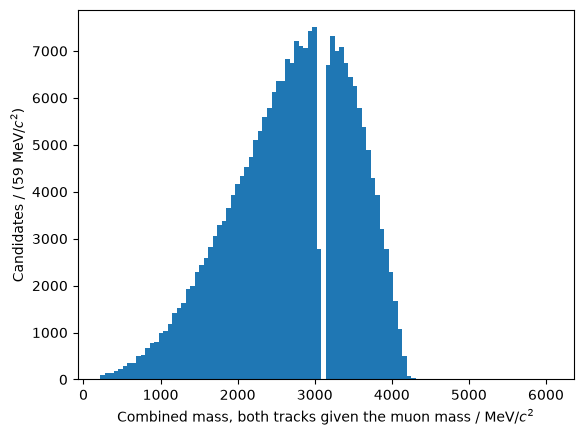

In [ ]:
#Veto candidates where the kaon + muon look like a J/psi (the kaon was really a muon)
jpsi_swap_veto = abs(kmu_mass_as_mumu - M_JPSI) > 50

plot_mass(kmu_mass_as_mumu[passes_bdt & jpsi_swap_veto], r'Combined mass, both tracks given the muon mass / MeV/$c^2$')

## ψ(2S) with the kaon and a muon swapped
Exactly the same mistake as the J/ψ above, but for B → ψ(2S) K: one of the ψ(2S) muons is recorded as the "kaon", and the real kaon as a muon.
The dimuon vetoes don't catch it, because the pair *labelled* as the two muons is not really the ψ(2S) pair.
If we give the "kaon" the muon mass, the "kaon" + μ⁻ pair is really the ψ(2S)'s two muons, so these events pile up at the ψ(2S) mass (3686 MeV).

There are about 12× fewer ψ(2S) than J/ψ decays, so this peak is much smaller than the J/ψ one. We fit it with a Gaussian plus an exponential to check that it is really there.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_13, Composed_autoparam_14]] data=[<zfit.Data: Data obs=('psi2s swap mass',) shape=(539, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00012 │          3006.76 |  10017.24 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                          value  (rounded)        hesse    at limit
--------------------------  ------------------  -----------  ----------
psi2s_swap_yield                       38.6586  +/-      16       False
psi2s_swap_backgroundYield              500.44  +/-      27       False
psi2s_swap_mean

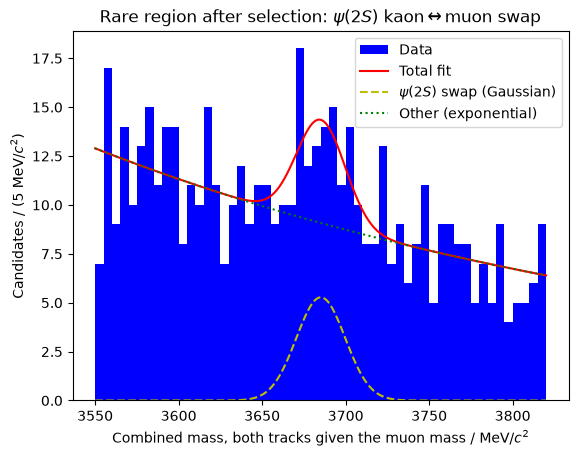

In [ ]:
#Candidates in the rare region after the selection and the J/psi swap veto
rare_selected = not_jpsi & not_psi2s & passes_bdt & jpsi_swap_veto

#Same mass as for the J/psi swap: both tracks given the muon mass. Zoom in around the psi(2S)
psi2s_swap_space = zfit.Space('psi2s swap mass', (3550, 3820))

psi2s_swap_mean  = zfit.Parameter('psi2s_swap_mean',  3686, 3650, 3720)
psi2s_swap_sigma = zfit.Parameter('psi2s_swap_sigma', 15,   3,    50)
psi2s_swap_yield = zfit.Parameter('psi2s_swap_yield', 50,   0,    1e6)
psi2s_swap_lam   = zfit.Parameter('psi2s_swap_exponent', -0.002, -0.1, 0.1)
psi2s_swap_bkg   = zfit.Parameter('psi2s_swap_backgroundYield', 500, 0, 1e6)

psi2s_swap_peak = zfit.pdf.Gauss(obs=psi2s_swap_space, mu=psi2s_swap_mean, sigma=psi2s_swap_sigma, extended=psi2s_swap_yield)
psi2s_swap_flat = zfit.pdf.Exponential(obs=psi2s_swap_space, lam=psi2s_swap_lam, extended=psi2s_swap_bkg)
psi2s_swap_PDF  = zfit.pdf.SumPDF([psi2s_swap_peak, psi2s_swap_flat])

result_psi2s_swap = fit_and_plot(kmu_mass_as_mumu[rare_selected], psi2s_swap_PDF,
                                 components={r'$\psi(2S)$ swap (Gaussian)': psi2s_swap_peak, 'Other (exponential)': psi2s_swap_flat},
                                 bins=54, xlabel=r'Combined mass, both tracks given the muon mass / MeV/$c^2$',
                                 title=r'Rare region after selection: $\psi(2S)$ kaon$\leftrightarrow$muon swap')

There is a small peak at the ψ(2S) mass. We remove it in the same way as the J/ψ swap: cut out ±50 MeV around 3686 MeV. That is about 3σ of the ψ(2S) peak width (15.8 MeV from the Crystal Ball fit in Task 2), the same as the window used for the J/ψ swap.

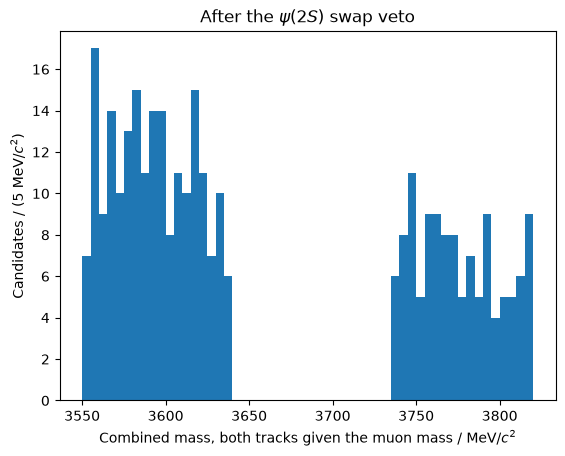

In [ ]:
#Veto candidates where the kaon + muon look like a psi(2S) (the kaon was really a muon)
psi2s_swap_veto = abs(kmu_mass_as_mumu - M_PSI2S) > 50

plot_mass(kmu_mass_as_mumu[rare_selected & psi2s_swap_veto], r'Combined mass, both tracks given the muon mass / MeV/$c^2$',
          bins=54, range=(3550, 3820), title=r'After the $\psi(2S)$ swap veto')

## D⁰ → K⁺π⁻ with the pion mistaken for a muon
D⁰ mesons are very common in B decays (e.g. B⁺ → D̄⁰ π⁺, or B⁺ → D̄⁰ μ⁺ ν), and a D̄⁰ often decays to K⁺π⁻.
Pions are sometimes mistaken for muons, because they can decay into a muon or travel far enough to reach the muon detectors. If the π⁻ is recorded as our μ⁻, the event can look like a B → K μμ candidate.

To find these, we give the μ⁻ the **pion mass** and recompute the K⁺ + "μ⁻" mass. Real D⁰ decays pile up at the D⁰ mass (1865 MeV).

As a check, we do the same with the *other* muon (the same-sign μ⁺). A K⁺ and a π⁺ can't come from a D⁰ (the charges don't add up to zero), so there should be **no** peak there.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_16, Composed_autoparam_17]] data=[<zfit.Data: Data obs=('K pi mass',) shape=(500, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.6e-05 │          2475.70 |  9995.472 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                  value  (rounded)        hesse    at limit
------------------  ------------------  -----------  ----------
d0_yield                       158.449  +/-      18       False
d0_backgroundYield             341.664  +/-      23       False
d0_mean                        1865.23  +/-       1  

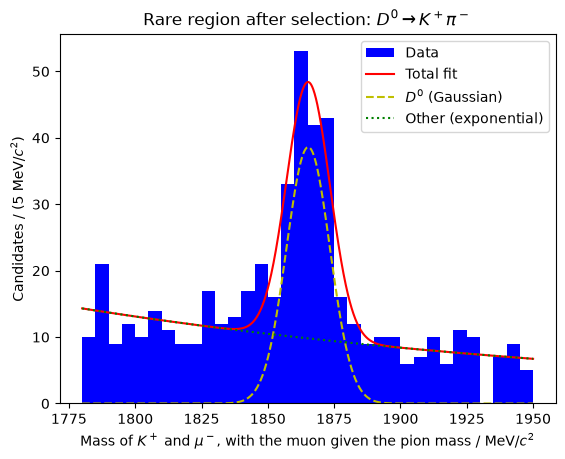

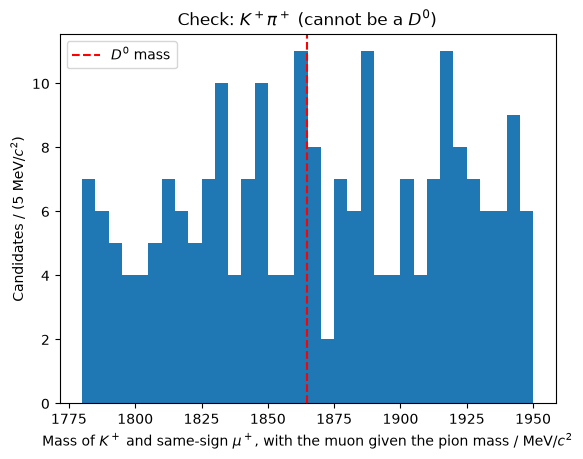

In [ ]:
#K+ and the opposite-sign "muon", with the muon given the pion mass
kpi_mass = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_PION)

d0_space = zfit.Space('K pi mass', (1780, 1950))

d0_mean  = zfit.Parameter('d0_mean',  1865, 1840, 1890)
d0_sigma = zfit.Parameter('d0_sigma', 8,    1,    40)
d0_yield = zfit.Parameter('d0_yield', 100,  0,    1e6)
d0_lam   = zfit.Parameter('d0_exponent', -0.003, -0.1, 0.1)
d0_bkg   = zfit.Parameter('d0_backgroundYield', 500, 0, 1e6)

d0_peak = zfit.pdf.Gauss(obs=d0_space, mu=d0_mean, sigma=d0_sigma, extended=d0_yield)
d0_flat = zfit.pdf.Exponential(obs=d0_space, lam=d0_lam, extended=d0_bkg)
d0_PDF  = zfit.pdf.SumPDF([d0_peak, d0_flat])

result_d0 = fit_and_plot(kpi_mass[rare_selected & psi2s_swap_veto], d0_PDF,
                         components={r'$D^0$ (Gaussian)': d0_peak, 'Other (exponential)': d0_flat},
                         bins=34, xlabel=r'Mass of $K^+$ and $\mu^-$, with the muon given the pion mass / MeV/$c^2$',
                         title=r'Rare region after selection: $D^0 \to K^+\pi^-$')

d0_mu_fit    = result_d0.params[d0_mean]['value']
d0_sigma_fit = result_d0.params[d0_sigma]['value']

#Check: K+ with the SAME-sign muon given the pion mass. K+ pi+ can't be a D0, so no peak is expected
kpi_mass_samesign = two_body_mass(data, 'Kaon', 'Same-sign muon', M_KAON, M_PION)
plt.axvline(M_D0, color='red', linestyle='--', label=r'$D^0$ mass')
plt.legend()
plot_mass(kpi_mass_samesign[rare_selected & psi2s_swap_veto], r'Mass of $K^+$ and same-sign $\mu^+$, with the muon given the pion mass / MeV/$c^2$',
          bins=34, range=(1780, 1950), title=r'Check: $K^+\pi^+$ (cannot be a $D^0$)')

There is a clear peak at the D⁰ mass, about 8 MeV wide, and no peak in the check with the other muon, so these really are D⁰ → K⁺π⁻ decays.
We cut out ±25 MeV around the D⁰ mass, which is about 3σ of the fitted width.

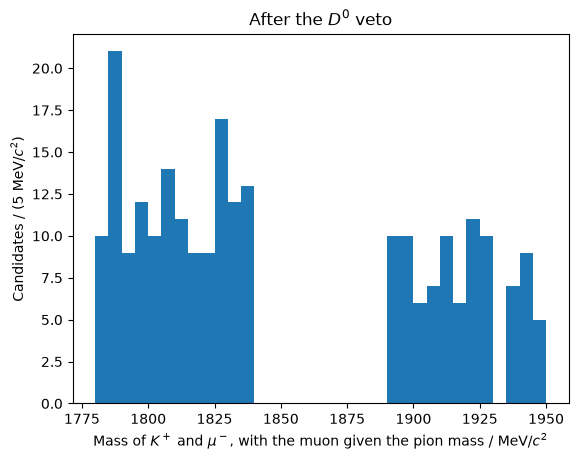

In [ ]:
#Veto candidates where the K+ and the "mu-" look like a D0 -> K+ pi- decay
d0_veto = abs(kpi_mass - M_D0) > 25

plot_mass(kpi_mass[rare_selected & psi2s_swap_veto & d0_veto],
          r'Mass of $K^+$ and $\mu^-$, with the muon given the pion mass / MeV/$c^2$',
          bins=34, range=(1780, 1950), title=r'After the $D^0$ veto')

## Task 6: Finalising the B count

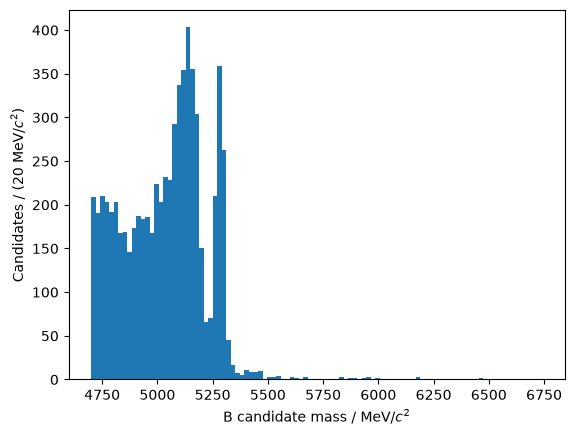

In [ ]:
#All cuts for the rare B -> K mu mu decay together
keep = (not_jpsi            #dimuon not a J/psi
    & not_psi2s             #dimuon not a psi(2S)
    & passes_bdt            #XGBoost selection
    & jpsi_swap_veto        #kaon + muon not a J/psi
    & psi2s_swap_veto       #kaon + muon not a psi(2S)
    & d0_veto               #kaon + muon (as a pion) not a D0
)

plot_mass(b_mass[keep], r'B candidate mass / MeV/$c^2$')

### The bump below the B peak
After all the cuts there is a large bump at about 5000–5200 MeV, below the B peak at 5280 MeV. It is background, and it comes from two kinds of real B decays:

1. **B decays where a particle was missed**, e.g. B → K* μμ, where the K* decays to K π and the pion is not picked up. Losing the pion's energy makes the B mass come out too low. This kind can't be heavier than the B mass minus the pion mass, about 5140 MeV, so it stops at about 5180 MeV.
2. **B → J/ψ K decays where the J/ψ gave off a photon.** These reach up to about 5240 MeV. The next markdown explains them.

There are two ways to deal with it:
- **Option A:** just cut away everything below 5220 MeV and fit what is left.
- **Option B:** first remove the J/ψ photon events with a "photon veto", then cut away everything below 5180 MeV and fit what is left.

Both fits use the same shape: a double-sided Crystal Ball for the B peak plus an exponential for the background. The Crystal Ball's width and tails are **fixed** to the values from the big B → J/ψ K fit in Task 1. The rare-decay sample is too small to measure them itself, and the peak should have the same shape in both decays (same B, same detector). Only the peak position, the two yields and the background slope are left free.

In [ ]:
def fit_rare_b_mass(values, lower, name, upper=5700):
    #Fit the B mass between `lower` and `upper` with a double-sided Crystal Ball (shape fixed from the
    #B -> J/psi K fit in Task 1) plus an exponential. `name` keeps the parameter names of each fit different.
    #Returns the fit result and the signal-yield parameter.
    space = zfit.Space('B invariant mass', (lower, upper))

    #Fixed shape, copied from the Task 1 fit (floating=False means the fit can't change them)
    fixed = {p: zfit.Parameter(f'{name}_{p}', result_b_cb.params[par]['value'], floating=False)
             for p, par in [('sigma', b_cb_sigma), ('alphaL', b_cb_alphaL), ('nL', b_cb_nL),
                            ('alphaR', b_cb_alphaR), ('nR', b_cb_nR)]}

    mean         = zfit.Parameter(f'{name}_mean', b_cb_mu_fit, 5250, 5320)
    signal_yield = zfit.Parameter(f'{name}_signalYield', 500, 0, 1e6)
    signal = zfit.pdf.DoubleCB(obs=space, mu=mean, sigma=fixed['sigma'],
                               alphal=fixed['alphaL'], nl=fixed['nL'], alphar=fixed['alphaR'], nr=fixed['nR'],
                               extended=signal_yield)

    exponent         = zfit.Parameter(f'{name}_exponent', -0.003, -0.1, 0.1)
    background_yield = zfit.Parameter(f'{name}_backgroundYield', 200, 0, 1e6)
    background = zfit.pdf.Exponential(obs=space, lam=exponent, extended=background_yield)

    total = zfit.pdf.SumPDF([signal, background])
    result = fit_and_plot(values, total,
                          components={'Signal (double Crystal Ball)': signal, 'Background (exponential)': background},
                          bins=int((upper - lower) / 10), xlabel=r'B candidate mass / MeV/$c^2$',
                          title=f'Rare B decays, fit from {lower} MeV', show_pulls=True)
    print(f'\nSignal yield: {result.params[signal_yield]["value"]:.0f} +/- {result.params[signal_yield]["hesse"]["error"]:.0f}')
    return result, signal_yield

### Option A: chop at 5220 MeV
The simplest choice: start the fit at 5220 MeV, above almost all of the bump. A few tens of J/ψ photon events (see below) are still left in the first 20 MeV of the fit range. They are a few percent of the signal, and the exponential absorbs some of them, so they could only push the signal count up slightly.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_19, Composed_autoparam_20]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1061, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.2e-05 │          5138.79 |  9878.189 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                      value  (rounded)        hesse    at limit
----------------------  ------------------  -----------  ----------
rare_A_signalYield                 894.637  +/-      35       False
rare_A_backgroundYield             166.369  +/-      22       False
rare_A_mean                  

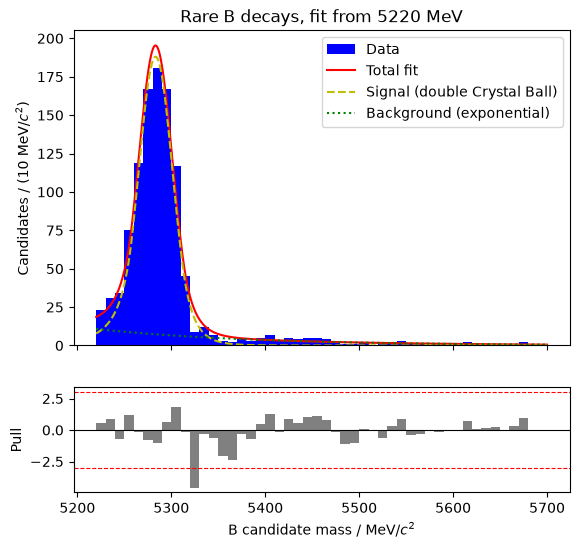


Signal yield: 895 +/- 35


In [ ]:
chop_A = 5220
result_A, yield_A = fit_rare_b_mass(b_mass[keep], chop_A, 'rare_A')
n_rare_A = result_A.params[yield_A]['value']

### Option B: the photon veto, then chop at 5180 MeV

**What goes wrong.** In a B → J/ψ K decay, the J/ψ sometimes gives off a photon (a particle of light) as it decays to two muons. The detector doesn't see the photon. So the energy the photon carried away is missing from our calculation, and two masses come out too low **at the same time**:
- the **dimuon mass** comes out below 3097 MeV. If the photon took more than about 100 MeV, it falls below our J/ψ veto window, so the event is no longer removed as a J/ψ;
- the **B mass** comes out too low by about the same amount, so it lands in the bump below the B peak.

**The trick.** Both masses drop by about the same amount (the photon's energy), so the **gap between them stays the same**, like two people standing on a staircase who both step down one stair: their heights change, but the difference in their heights doesn't. For these events

  B mass − dimuon mass ≈ 5284 − 3100 ≈ **2184 MeV**, no matter how much energy the photon took.

The same thing happens for B → ψ(2S) K, where the gap stays at 5284 − 3690 ≈ **1594 MeV**.

**The photon veto** removes every candidate whose gap is within ±100 MeV of 2184 or 1594 (the same ±100 MeV as our J/ψ and ψ(2S) vetoes).

**Why it doesn't remove real rare decays in the B peak.** A real rare decay has the *correct* B mass, about 5284 MeV. For its gap to be 2184 ± 100, its dimuon mass would have to be 3100 ± 100, and those events were already removed by the J/ψ veto. So the photon veto costs (almost) no signal, and it is much better than just making the J/ψ veto wider, which *would* throw away real rare decays.

With the photon events gone, only the "missed particle" decays like B → K* μμ are left in the bump, and they stop at about 5180 MeV, so we can start the fit lower than in Option A.

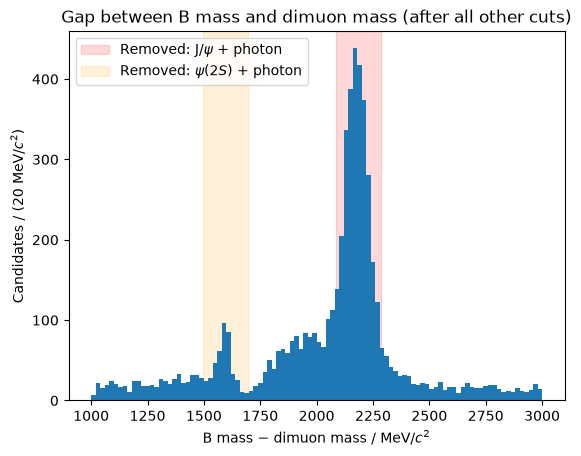

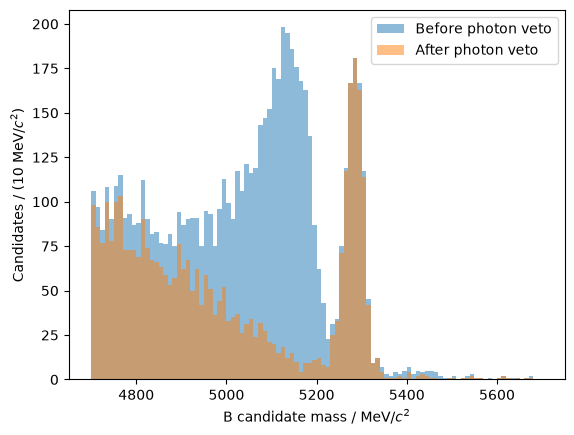

Photon veto removes 3294 candidates, of which 23 are in the B peak window


In [ ]:
#Gap between the B mass and the dimuon mass. For J/psi (or psi(2S)) events that lost a photon it stays the same
mass_difference = b_mass - dimuon_mass
jpsi_gap  = b_cb_mu_fit - jpsi_cb_mu_fit     #about 2184 MeV
psi2s_gap = b_cb_mu_fit - psi2s_cb_mu_fit    #about 1594 MeV

photon_veto = (abs(mass_difference - jpsi_gap) > 100) & (abs(mass_difference - psi2s_gap) > 100)

#Before the veto: two spikes at the J/psi and psi(2S) gaps
plt.axvspan(jpsi_gap - 100, jpsi_gap + 100, color='red', alpha=0.15, label=r'Removed: J/$\psi$ + photon')
plt.axvspan(psi2s_gap - 100, psi2s_gap + 100, color='orange', alpha=0.15, label=r'Removed: $\psi(2S)$ + photon')
plt.legend()
plot_mass(mass_difference[keep], r'B mass $-$ dimuon mass / MeV/$c^2$', bins=100, range=(1000, 3000),
          title='Gap between B mass and dimuon mass (after all other cuts)')

#B mass before and after the photon veto
plt.hist(b_mass[keep], bins=100, range=(4700, 5700), alpha=0.5, label='Before photon veto')
plt.hist(b_mass[keep & photon_veto], bins=100, range=(4700, 5700), alpha=0.5, label='After photon veto')
plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(r'Candidates / (10 MeV/$c^2$)')
plt.legend()
plt.show()

in_peak = abs(b_mass - b_cb_mu_fit) < 3*b_cb_sigma_fit
print(f'Photon veto removes {int((keep & ~photon_veto).sum())} candidates, '
      f'of which {int((keep & ~photon_veto & in_peak).sum())} are in the B peak window')

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_22, Composed_autoparam_23]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1019, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.4e-05 │          4870.57 |  9864.942 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                      value  (rounded)        hesse    at limit
----------------------  ------------------  -----------  ----------
rare_B_signalYield                   928.2  +/-      33       False
rare_B_backgroundYield             90.7713  +/-      15       False
rare_B_mean                  

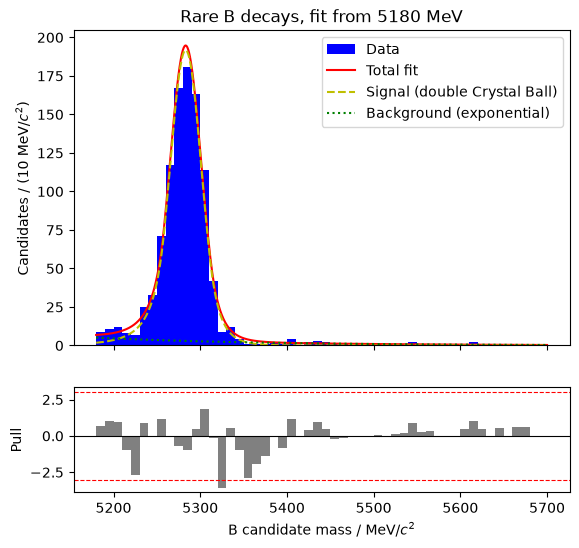


Signal yield: 928 +/- 33


In [ ]:
chop_B = 5180
result_B, yield_B = fit_rare_b_mass(b_mass[keep & photon_veto], chop_B, 'rare_B')
n_rare_B = result_B.params[yield_B]['value']

### Raw asymmetry of the rare decay: one fit to B⁺ and B⁻ at the same time
We use Option B (photon veto, fit from 5180 MeV) as the main result.

We split the candidates by the kaon's charge (`Kaon assumed particle type`: +321 is a K⁺, so a **B⁺**; −321 is a K⁻, so a **B⁻**) and fit **both halves at once**:
- The signal shape is the **same** for B⁺ and B⁻ (same B mass, same detector), so any difference between the two halves comes only from the numbers of events.
- Instead of a separate signal yield for each half, the fit uses the **total** N = N(B⁺) + N(B⁻) and the **raw asymmetry**

  A_raw = (N(B⁻) − N(B⁺)) / (N(B⁻) + N(B⁺)),

  so that N(B⁻) = N(1 + A)/2 and N(B⁺) = N(1 − A)/2. The fit then gives A_raw and its uncertainty directly, with no error propagation needed.
- Each half has its own amount of background, with the same background slope.

"Raw" means it still includes fake asymmetries from how B mesons are produced and detected. Task 7 measures those, and Task 8 removes them.

In [ ]:
def fit_charge_asymmetry(values, kaon_type, lower, name, title, fix_shape=True, upper=5700):
    #Fit the B mass of B+ and B- candidates at the same time and return the raw asymmetry A and its uncertainty.
    #values:    B masses of the selected candidates
    #kaon_type: 'Kaon assumed particle type' of the same candidates (+321 = B+, -321 = B-)
    #fix_shape: True  = signal width and tails fixed from the Task 1 fit (for small samples)
    #           False = they float, starting from the Task 1 values (for big samples), but are still shared by B+ and B-
    space = zfit.Space('B invariant mass', (lower, upper))

    limits = {'sigma': (1, 100), 'alphaL': (0.1, 10), 'nL': (0.5, 100), 'alphaR': (0.1, 10), 'nR': (0.5, 100)}
    shape = {}
    for p, par in [('sigma', b_cb_sigma), ('alphaL', b_cb_alphaL), ('nL', b_cb_nL), ('alphaR', b_cb_alphaR), ('nR', b_cb_nR)]:
        start = result_b_cb.params[par]['value']
        if fix_shape:
            shape[p] = zfit.Parameter(f'{name}_{p}', start, floating=False)
        else:
            shape[p] = zfit.Parameter(f'{name}_{p}', start, *limits[p])
    mean     = zfit.Parameter(f'{name}_mean', b_cb_mu_fit, 5250, 5320)
    exponent = zfit.Parameter(f'{name}_exponent', -0.003, -0.1, 0.1)   #same background slope for B+ and B-

    values, kaon_type = np.asarray(values), np.asarray(kaon_type)
    in_range = (values >= lower) & (values <= upper)

    #Signal yields written as total N and asymmetry A
    N = zfit.Parameter(f'{name}_N', in_range.sum(), 0, 1e8)
    A = zfit.Parameter(f'{name}_A', 0, -1, 1)
    n_signal = {
        'B+': zfit.ComposedParameter(f'{name}_N_Bplus',  lambda p: p['N'] * (1 - p['A']) / 2, params={'N': N, 'A': A}),
        'B-': zfit.ComposedParameter(f'{name}_N_Bminus', lambda p: p['N'] * (1 + p['A']) / 2, params={'N': N, 'A': A}),
    }

    models, datasets, parts = [], [], []
    for charge, kaon_id, tag in (('B+', 321, 'Bplus'), ('B-', -321, 'Bminus')):
        charge_values = values[in_range & (kaon_type == kaon_id)]
        signal = zfit.pdf.DoubleCB(obs=space, mu=mean, sigma=shape['sigma'],
                                   alphal=shape['alphaL'], nl=shape['nL'], alphar=shape['alphaR'], nr=shape['nR'],
                                   extended=n_signal[charge])
        background_yield = zfit.Parameter(f'{name}_backgroundYield_{tag}', 0.1 * len(charge_values) + 1, 0, 1e8)
        background = zfit.pdf.Exponential(obs=space, lam=exponent, extended=background_yield)
        model = zfit.pdf.SumPDF([signal, background])

        models.append(model)
        datasets.append(zfit.Data.from_numpy(obs=space, array=charge_values))
        parts.append((charge, charge_values, model, signal, background))

    #One likelihood for both datasets: the fit chooses N, A and everything else to describe B+ and B- together
    nll = zfit.loss.ExtendedUnbinnedNLL(model=models, data=datasets)
    result = zfit.minimize.Minuit().minimize(nll)
    result.hesse()
    print(result)
    print(f"Valid: {result.valid}")
    if not result.valid:
        print('WARNING: the fit is not valid, do not trust these numbers.')

    for charge, charge_values, model, signal, background in parts:
        plot_fit(charge_values, model, components={'Signal (double Crystal Ball)': signal, 'Background (exponential)': background},
                 bins=int((upper - lower) / 10), xlabel=r'B candidate mass / MeV/$c^2$', title=f'{title}: {charge}', show_pulls=True)

    a, a_err = result.params[A]['value'], result.params[A]['hesse']['error']
    print(f"N(B+) = {float(n_signal['B+'].value()):.0f}, N(B-) = {float(n_signal['B-'].value()):.0f}")
    print(f'Raw asymmetry A = {a:.4f} +/- {a_err:.4f}')
    return a, a_err, result

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_31, Composed_autoparam_32], <zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_34, Composed_autoparam_35]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(504, 1)>, <zfit.Data: Data obs=('B invariant mass',) shape=(515, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 7.7e-06 │          4874.15 |  10011.74 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                                value  (rounded)        hesse    at limit
--------------------------------  ------------------  -----------

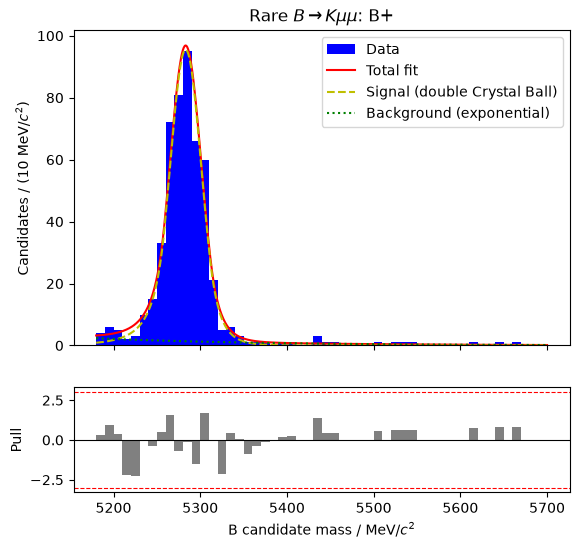

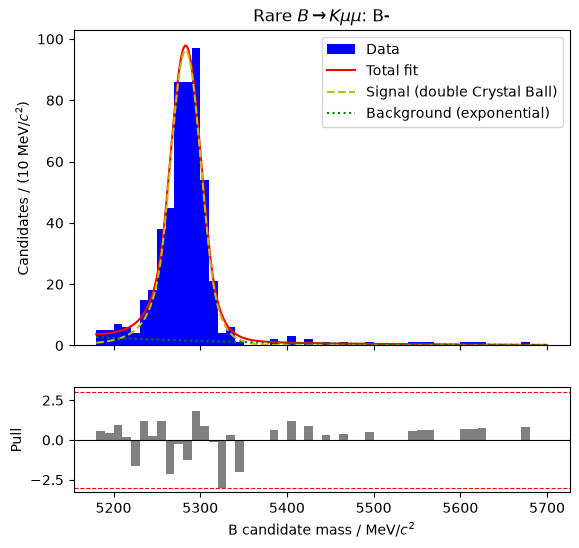

N(B+) = 462, N(B-) = 466
Raw asymmetry A = 0.0041 +/- 0.0344


In [ ]:
#Rare decay: Option B sample (all cuts + photon veto), fit from chop_B, shape fixed from Task 1
rare_sample = keep & photon_veto
A_raw_rare, A_raw_rare_err, result_asym_rare = fit_charge_asymmetry(
    b_mass[rare_sample], data['Kaon assumed particle type'][rare_sample],
    chop_B, 'asym_rare', r'Rare $B \to K \mu\mu$', fix_shape=True)

## Task 7: CP asymmetry of B⁺ → J/ψ K⁺ (the "fake asymmetry")
Even if nature treated B⁺ and B⁻ exactly the same, we would not count equal numbers of them:
- **Production:** the LHC collides protons (matter), so B⁺ and B⁻ are not made in exactly equal numbers.
- **Detection:** K⁺ and K⁻ interact slightly differently with the detector material, so they are not found equally efficiently.

B⁺ → J/ψ K⁺ (with J/ψ → μ⁺μ⁻) has **exactly the same final particles** as the rare decay (a kaon and two muons) and is selected in the same way, so it suffers the **same** fake asymmetry. Its real CP asymmetry is predicted (and measured) to be essentially zero, so whatever raw asymmetry we measure for it is the fake part.

The J/ψ K sample uses **exactly the same cuts as the rare decay, with two exceptions**:
- the dimuon mass must be **in** the J/ψ peak (instead of vetoed);
- **no photon veto**: every real J/ψ K event has a B mass − dimuon mass gap of about 2184 MeV, so the photon veto would remove all of them.

There are about 300× more J/ψ K than rare decays, so here the signal shape is left free (but still shared by B⁺ and B⁻), and the uncertainty on its asymmetry is tiny. A clearly non-zero result does **not** mean CP violation: it is the production and detection asymmetry.

(Some of these J/ψ K events were used to train XGBoost, so they score slightly too high. That affects B⁺ and B⁻ in the same way, so it does not change the asymmetry.)

B -> J/psi K candidates: 196089
FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_37, Composed_autoparam_38], <zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_40, Composed_autoparam_41]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(73091, 1)>, <zfit.Data: Data obs=('B invariant mass',) shape=(71207, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00057 │        635827.67 | -129.2599 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                                 value  (rounded)        hesse    at limit
----------------------------

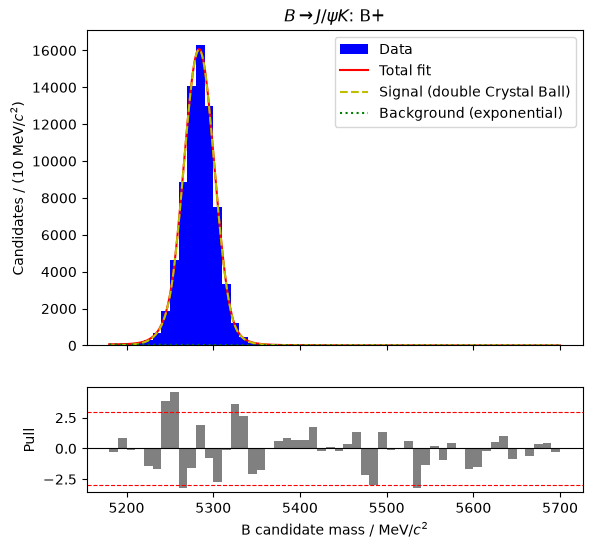

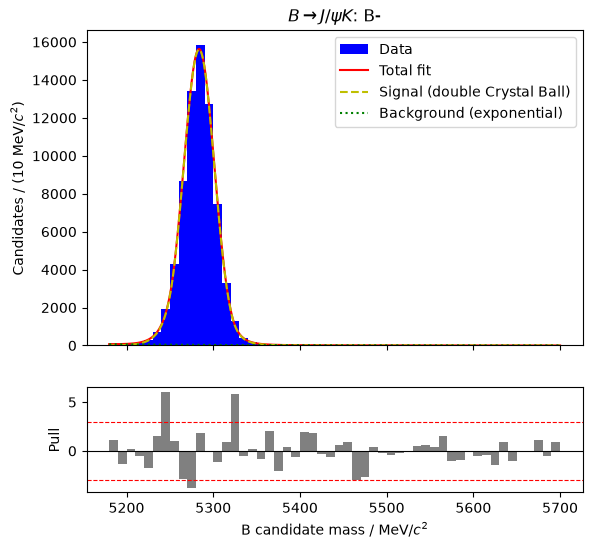

N(B+) = 72323, N(B-) = 70335
Raw asymmetry A = -0.0139 +/- 0.0027


In [ ]:
#Same cuts as the rare decay, but the dimuon mass IN the J/psi peak and no photon veto
jpsi_k_sample = in_jpsi_peak & passes_bdt & jpsi_swap_veto & psi2s_swap_veto & d0_veto
print(f'B -> J/psi K candidates: {int(jpsi_k_sample.sum())}')

A_raw_jpsik, A_raw_jpsik_err, result_asym_jpsik = fit_charge_asymmetry(
    b_mass[jpsi_k_sample], data['Kaon assumed particle type'][jpsi_k_sample],
    chop_B, 'asym_jpsik', r'$B \to J/\psi K$', fix_shape=False)

## Task 8: CP asymmetry of the rare decay
Both decays have the same fake asymmetry, so we remove it by subtracting:

  **A_CP(B → K μμ) = A_raw(B → K μμ) − A_raw(B → J/ψ K)**

(this uses the fact that the real CP asymmetry of B → J/ψ K is about zero). The two uncertainties are independent, so they are combined in quadrature. The rare decay's uncertainty is much larger, so it dominates.

The Standard Model predicts A_CP(B → K μμ) to be very close to zero. A clearly non-zero value would hint at new physics. For comparison, LHCb's published measurement with 3 fb⁻¹ (2011 + 2012) is A_CP = 0.012 ± 0.017 (stat) ± 0.001 (syst) [JHEP 09 (2014) 177].

The uncertainty here is **statistical only**. Systematic uncertainties (fit shape, fit range, cut choices, how well the two decays' kinematics match) still need to be added.

In [ ]:
A_CP_rare     = A_raw_rare - A_raw_jpsik
A_CP_rare_err = np.sqrt(A_raw_rare_err**2 + A_raw_jpsik_err**2)

print(tabulate([
    (r'A_raw(B -> K mu mu)',    A_raw_rare,  A_raw_rare_err),
    (r'A_raw(B -> J/psi K)',    A_raw_jpsik, A_raw_jpsik_err),
    (r'A_CP(B -> K mu mu)',     A_CP_rare,   A_CP_rare_err),
], headers=['Quantity', 'Value', 'Stat. uncertainty'], floatfmt='.4f'))

print(f'\nA_CP(B -> K mu mu) = {A_CP_rare:.3f} +/- {A_CP_rare_err:.3f} (stat), '
      f'which is {abs(A_CP_rare) / A_CP_rare_err:.1f} standard deviations from zero')

Quantity               Value    Stat. uncertainty
-------------------  -------  -------------------
A_raw(B -> K mu mu)   0.0041               0.0344
A_raw(B -> J/psi K)  -0.0139               0.0027
A_CP(B -> K mu mu)    0.0180               0.0345

A_CP(B -> K mu mu) = 0.018 +/- 0.035 (stat), which is 0.5 standard deviations from zero
